# From a cutoff and a filtrate fraction to a photomask
### Controlled Incremental Filtration (CIF) with opencif 1.0.0: a tutorial

A CIF device sorts suspended particles by size. A suspension flows along a straight center channel whose two walls
are rows of posts. The opening between two neighboring posts is a 'gap', and beyond each row of posts runs a side
channel. At each gap, a thin layer of fluid next to the wall (the 'lamina', of width $\delta$) leaves the center
channel through the gap and enters the side channel, while the rest of the fluid flows on. After hundreds or thousands
of gap rows, a chosen share of the fluid, often more than half, has left through the sides as 'filtrate', and what
remains in the center channel is the 'retentate'. Gifford et al. (*Lab Chip* 2014) introduced the design, and Xia et
al. (*Sci. Rep.* 2016) and Dinh et al. (*Lab Chip* 2024) built devices with it.

Skimming a thin wall layer sorts by size because a sphere of radius $a$ cannot bring its center closer to the wall
than $a$. If $a$ exceeds the lamina's width, the center of the sphere rides a streamline outside the lamina, so the
sphere never leaves with the lamina and is retained. A smaller sphere can have its center inside the lamina and is
carried out with the filtrate. Thus, the lamina's width sets a cutoff diameter $D$. The lamina carries a small
fraction $f$ of the center flow, so the fraction that each gap takes sets the lamina's width and with it the cutoff,
whereas the number of gap rows $N$ sets how much of the fluid leaves in all. Figure 1, at the start of section 2,
shows one gap of the upper wall, the lamina that leaves through it, and two particles that start against the wall. The
ideal (steric) picture gives $D = 2\delta$, whereas the measured devices give $D = \kappa_g\,\delta$ with
$\kappa_g = 4.9138$, and section 3 gives the numbers.

A CIF device is defined by two numbers. The first is the cutoff $D$ (the glossary's $d_{\mathrm{crit}}$), the diameter
above which particles are retained, which is set by how thick a layer each gap skims and therefore by the small
fraction $f$ of the center flow that each gap takes (a few parts in ten thousand). The second is the filtrate fraction
$F$, the share of the inlet flow that leaves through the side channels, which is set by the number of gap rows $N$,
since each row takes $2f$ of what is left and, for a constant $f$, $F = 1-(1-2f)^N$. The two are decoupled, since $D$
fixes $f$ at every row and $F$ then fixes only $N$ (Appendix A, Results 8 and 13; Appendix B, claims C4 and C8). This
decoupling is why the generator takes just the pair $(D, F)$. Everything else, including the side channels' widths row
by row, the inlet, the outlets, and the folds that fit the device on a chip, follows from those two numbers, the
fabrication process (how deep and how fine the channels can be made), and a layout choice. The generator draws the
device, measures its own drawing, solves the flow on the drawing to check that every gap skims what the design asked,
and then audits the photomask file that it wrote.

This notebook takes the reader from those two numbers to a photomask (a DXF file that a mask shop can print), checks
every step, and then audits the photomask itself, read back from its file. The code is opencif 1.0.0, taken from the
repository that holds this notebook in its `notebooks/` folder, and section 1 prints and checks its code stamp. Every
equation below is traced to the texts that the code cites, which are in the repository's `foundation/` folder: Appendix
A ("Step-by-Step Derivations Behind Controlled Incremental Filtration", Results 1–15), Appendix B (the argument, claims
C1–C9), and the glossary, all three frozen on 2026-09-29. The trace suite `tests/test_appendix_trace.py` pins the code
to them and checks the texts' md5 sums. Nothing in this notebook adds physics. The notebook calls the package's
functions and prints what they compute, and where it computes an equation itself (sections 3.1, 3.2, 4.1, 4.2, 4.4, and
4.5), it does so to compare the result with Appendix A's worked examples or with the package.

Six terms recur below that belong to the dissertation's vocabulary. The 'validity envelope' is the range of designs
over which the cutoff law was calibrated and the assumptions of the flow model hold, and the generator refuses designs
outside it (section 8). 'Q1' and 'Q2' are the two checks on the drawn photomask. Q1 requires that the flow network on
the drawing deliver the designed fractions, and Q2 requires that every gap's realized cutoff be within 1% of $D$ and
that the drawn device deliver $F$ within its tolerance (section 6). The 'junction band' (the '1-D model band' of
`docs/REFERENCE.md`) is the model's own uncertainty at bends and junctions, which is reported in brackets after a
verdict and is never a pass condition (section 6). The 'physics audit' is the design code's physics auditor, ported to
opencif, which reads every photomask back from its file and checks it (section 7). A 'declared departure' is a row
that a published design deliberately moves off the cutoff, such as a start rule or a head drawn as the paper drew it,
and such rows are listed rather than hidden (section 10). Finally, 'reproduce mode' is the mode in which the published
devices are drawn with their departures declared (section 10).

The notebook has fourteen sections.

1. Setup: loading and verifying the repository
2. The device and its vocabulary
3. The cutoff axis: from $D$ to the fraction each gap skims
4. The yield axis: from $F$ to the number of rows, and from flows to widths
5. The whole path in fewer than 300 lines: a straight ladder by hand
6. One call: from $(D, F)$ to a photomask
7. The physics audit: the photomask read back from its file
8. The validity envelope and the designs the generator refuses
9. Composing new devices from parts
10. Reproducing the published devices
11. opencif and the design code `CIF_v2.py`
12. Micrograph traces (the companion notebook)
13. Exercises
14. The reproducibility record

Section 1 gives the installation and the Python version. Sections 1 to 8 take about 10 to 20 minutes. Section 9
builds three new devices, which takes about 20 minutes, or up to 50 minutes while the builds of section 10 run beside
them. Section 10 builds the four published devices, which takes about 1 to 1.5 hours on two cores. For a first
reading, set `QUICK = True` at the top of the setup cell in section 1 (or set the environment variable
`OPENCIF_TUTORIAL_QUICK=1` before starting Jupyter), so that the published devices are planned in 3 to 5 minutes
rather than built. Sections 6 and 9 build their four devices in quick mode as well. The outputs are written to
`notebooks/tutorial_out/`.

## 1. Setup: loading and verifying the repository

The notebook requires Python 3.11 or later, Jupyter, and the package versions that `requirements-tested.txt` lists
(numpy 2.4.4, scipy 1.17.1, shapely 2.1.2, matplotlib 3.10.9, pyyaml 6.0.3, ezdxf 1.4.4, and pillow 12.2.0). To
install them, run `pip install -r requirements-tested.txt` in the repository's folder, and then start Jupyter in the
repository's `notebooks/` folder, because the setup cell finds the repository by searching upward from the working
folder and writes the outputs to `notebooks/tutorial_out/`. With Python 3.11 and the tested versions, a build
reproduces the release's photomasks byte for byte, because every shipped design was rebuilt with them and compared
(`README.md`; `docs/VALIDATION.md`). Under Python 3.13 with the same versions, an independent reviewer's run of the
tutorial of the preceding release candidate (RC8) obtained the same printed numbers and the same photomask bytes.
We do not promise identical output with other versions.

The cell below finds the repository that holds this notebook, imports its `opencif` package, and checks that the
package is the released code. Every record that opencif writes carries a 'code stamp', which is a sha256 over every
Python file of the package and its data, and `validation/RELEASE.json` holds the stamp of the release together with
the evidence of its validation (the photomasks' sha256 sums, the exit codes, and the audit results). The cell also
checks that the design code `reference/CIF_v2.py` is the frozen file that Appendix A names. If any file of the package
had been edited, the stamp would differ and the cell would say so. The first lines of the cell choose quick mode. Set
`QUICK = True` there for a first reading, so that the published devices of section 10 are planned in minutes rather
than built, and leave it `False` for the builds.

In [1]:
import os, sys, json, math, time, hashlib, subprocess, shutil, glob
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Set QUICK to True for a first reading, so that the published devices of section 10 are planned rather than built,
# which takes minutes instead of 1 to 1.5 hours. Leave it False for the builds. Setting the environment variable
# OPENCIF_TUTORIAL_QUICK=1 before starting Jupyter has the same effect.
QUICK = False
QUICK = QUICK or os.environ.get('OPENCIF_TUTORIAL_QUICK') == '1'
RUN_START = time.time()       # the files that section 14 lists as this run's are those written after this time

HERE = Path.cwd()
TREE = next(p for p in [HERE, *HERE.parents] if (p / 'opencif' / '__init__.py').exists())   # the repository
sys.path.insert(0, str(TREE))
import opencif
from opencif import pipeline as PL
RELEASE = json.load(open(TREE / 'validation' / 'RELEASE.json'))      # the release's code stamp and evidence
OUT = HERE / 'tutorial_out'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 9})

env = PL.ENV
md5 = hashlib.md5(open(TREE / 'reference' / 'CIF_v2.py', 'rb').read()).hexdigest()
print('opencif', opencif.__version__, '| code stamp', PL.CODE['sha256'], '| tests', env['tests_sha256'])
print('released code stamp (validation/RELEASE.json):', RELEASE['code_stamp'],
      '(this package is the released code)' if PL.CODE['sha256'] == RELEASE['code_stamp'] else
      '(THIS PACKAGE DIFFERS FROM THE RELEASED CODE, and its records will say so)')
print('the design code reference/CIF_v2.py, md5 %s (%s)' % (md5, 'the frozen v2.1.0' if md5 == '0e0961a50441afb94671b4470d41bace'
                                                            else 'NOT the frozen v2.1.0'))
print('Python', env['python'], '|', ', '.join('%s %s' % kv for kv in sorted(env['installed'].items())))
print('installed versions equal the tested ones (requirements-tested.txt):', env['matches_lock'])
print('quick mode (the published devices are planned rather than built):', QUICK)

opencif 1.0.0 | code stamp 9e4eb55a0affeef3 | tests 6340f50956101e9d
released code stamp (validation/RELEASE.json): 9e4eb55a0affeef3 (this package is the released code)
the design code reference/CIF_v2.py, md5 0e0961a50441afb94671b4470d41bace (the frozen v2.1.0)
Python 3.11.17 | ezdxf 1.4.4, matplotlib 3.10.9, numpy 2.4.4, pillow 12.2.0, pyyaml 6.0.3, scipy 1.17.1, shapely 2.1.2
installed versions equal the tested ones (requirements-tested.txt): True
quick mode (the published devices are planned rather than built): False


In [2]:
def preview(path, width=1100):
    '''Show a PNG scaled to `width` pixels. The file on disk keeps its full resolution.'''
    from PIL import Image as PILImage
    import io
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.convert('RGB').save(buf, format='PNG', optimize=True)
    display(Image(data=buf.getvalue()))
    print('(preview; full resolution: %s)' % os.path.relpath(path, HERE))


def show(fig, name):
    '''Display a figure inline as a PNG and keep the same PNG in tutorial_out/notebook_figures/<name>.png. The
    renderers of opencif select matplotlib's Agg backend, under which a Figure object would display only as text, so
    the figure is rendered to bytes here.'''
    import io
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
    plt.close(fig)
    data = buf.getvalue()
    (OUT / 'notebook_figures').mkdir(parents=True, exist_ok=True)
    (OUT / 'notebook_figures' / (name + '.png')).write_bytes(data)
    display(Image(data=data))


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for b in iter(lambda: fh.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()


import threading
REUSED = {}          # reproduction builds that an earlier run of this notebook had already finished (section 14 records them)
REPRO = ['dinh2024_v1_figure_aligned', 'gifford2014_fig4_aligned', 'gifford2014_fig6_aligned', 'xia2016_rs7_aligned']


def build_presets(names, workers=2, log_path=None):
    '''Build presets in separate processes, `workers` at a time, with the command python -m opencif build
    presets/<name>.yaml run in the repository's folder. A build that an earlier run finished here, and whose photomask
    has the released sha256, is not repeated.'''
    say = open(log_path, 'a') if log_path else sys.stdout
    stamp = lambda: time.strftime('%H:%M:%S')
    todo = []
    for n in names:
        dxf = OUT / 'repro' / n / (n + '.dxf')
        if dxf.exists() and (OUT / 'repro' / n / (n + '.json')).exists() and sha256(dxf) == FROZEN[n]['dxf_sha256']:
            rj_ = json.load(open(OUT / 'repro' / n / (n + '.json')))
            REUSED[n] = dict(code_stamp=(rj_.get('code') or {}).get('sha256'), written=time.ctime(os.path.getmtime(dxf)))
            print('%s %-28s already built here (sha256 verified)' % (stamp(), n), file=say, flush=True)
        else:
            todo.append(n)
    running, t0 = {}, time.time()
    while todo or running:
        while todo and len(running) < workers:
            n = todo.pop(0)
            (OUT / 'repro').mkdir(exist_ok=True)
            log = open(OUT / 'repro' / (n + '.log'), 'w')
            running[n] = (subprocess.Popen([sys.executable, '-m', 'opencif', 'build',
                                            str(TREE / 'presets' / (n + '.yaml')), '--out', str(OUT / 'repro' / n)],
                                           cwd=str(TREE), stdout=log, stderr=subprocess.STDOUT), log, time.time())
            print('%s %-28s started' % (stamp(), n), file=say, flush=True)
        for n, (p, log, ts) in list(running.items()):
            if p.poll() is not None:
                log.close()
                print('%s %-28s finished, exit %d, %.0f min' % (stamp(), n, p.returncode, (time.time() - ts) / 60),
                      file=say, flush=True)
                del running[n]
        time.sleep(10)
    print('%s all reproduction builds finished after %.0f min' % (stamp(), (time.time() - t0) / 60), file=say, flush=True)


FROZEN = RELEASE['photomasks']     # the release's own rebuild of every shipped spec (photomask sha256, exit code, N, F, and audit)
print(len(FROZEN), 'released builds on record, for example gifford2014_fig4_aligned:',
      {k: FROZEN['gifford2014_fig4_aligned'][k] for k in ('exit_code', 'N', 'F_design', 'dxf_sha256', 'physics_audit')})

54 released builds on record, for example gifford2014_fig4_aligned: {'exit_code': 0, 'N': 3543, 'F_design': 0.9064961035437347, 'dxf_sha256': 'edaf92626d574aea0dc9defed781e2f848def5c70fbaf9d70def345cc0ddf2e0', 'physics_audit': 'PASS'}


The four published devices take about 1 to 1.5 hours to build on two cores (section 10). The cell below starts their
builds now, in separate processes two at a time, so that they run in the background while the reader works through
sections 2 to 9, and section 10 collects them. In quick mode the cell starts nothing.

In [3]:
(OUT / 'repro').mkdir(exist_ok=True)
REPRO_LOG = OUT / 'repro' / 'builds.log'
repro_thread = None
if not QUICK:
    repro_thread = threading.Thread(target=build_presets, args=(REPRO, 2, REPRO_LOG), daemon=True)
    repro_thread.start()
    print('reproduction builds started in the background; their progress is logged in %s' % os.path.relpath(REPRO_LOG, HERE))

reproduction builds started in the background; their progress is logged in tutorial_out/repro/builds.log


## 2. The device and its vocabulary

Figure 1 shows how one gap sorts particles by size. Panel (a) is a plan view of one gap in the upper wall of the center
channel. The lamina (orange) is the fluid between the wall and the dashed dividing streamline, which ends on the corner
of the downstream post, so that all of the lamina leaves through the gap. A small particle (radius $a < \delta$) has its
center inside the lamina and leaves with it, whereas a large particle ($a > \delta$) keeps its center outside the lamina
and passes the gap. Panel (b) shows the parabolic velocity profile across the center channel, with the share of the flow
that the lamina carries, $f = 3x^2 - 2x^3$ with $x = \delta/w_c$, shaded (App. A, Result 1). The legend of the figure
states the steric cutoff $D = 2\delta$ (App. A, Result 5), whereas the measured devices give $D = \kappa_g\,\delta$ with
$\kappa_g = 4.9138$ (section 3.3). The sketch exaggerates the lamina about eight times so that it can be seen, because
in a device $x$ is about 0.01. The script `tools/tutorial_figures.py` draws the figure with matplotlib alone, and the
cell below runs it.

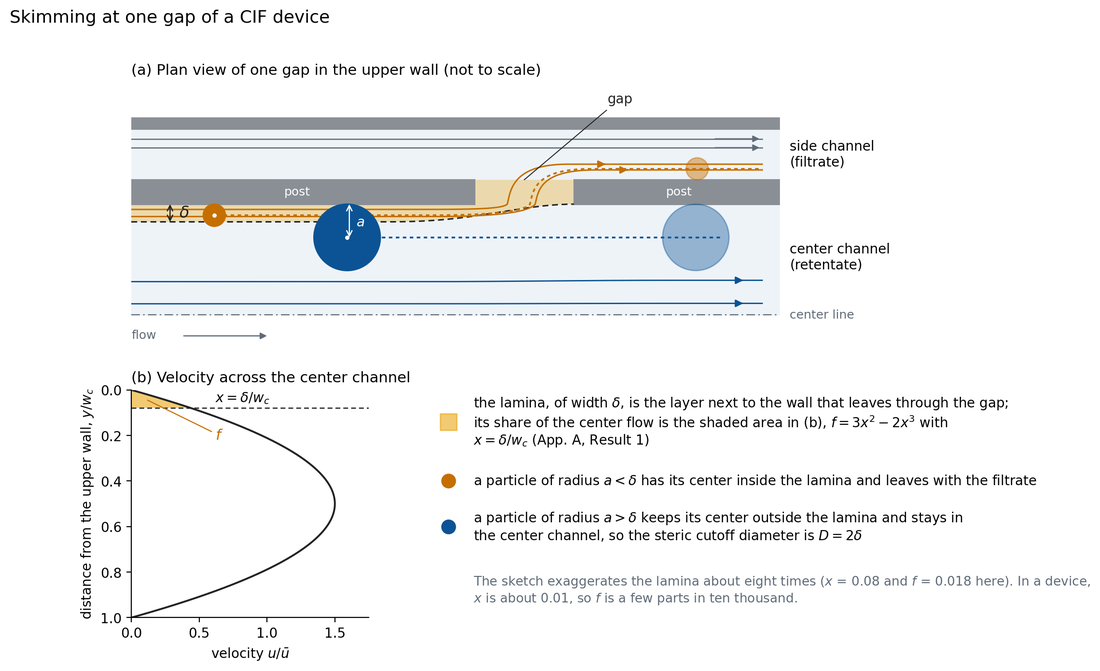

(preview; full resolution: tutorial_out/notebook_figures/lamina_sketch.png)


In [4]:
# Figure 1 is drawn by tools/tutorial_figures.py with matplotlib alone, so running it here also shows that the figure
# can be regenerated from the repository.
p_fig = subprocess.run([sys.executable, str(TREE / 'tools' / 'tutorial_figures.py'), str(OUT / 'notebook_figures')],
                       capture_output=True, text=True)
if p_fig.returncode != 0:
    raise RuntimeError('tools/tutorial_figures.py failed:\n' + p_fig.stderr)
preview(OUT / 'notebook_figures' / 'lamina_sketch.png')

Figure 2, drawn by the cell below, shows five gap rows of a straight device. It is not to scale, and the widths are
exaggerated. At each gap row $i$, the gap on each side skims the fraction $f(i)$ of the center flow, and the side
channel widens row by row because it carries more flow after every row.

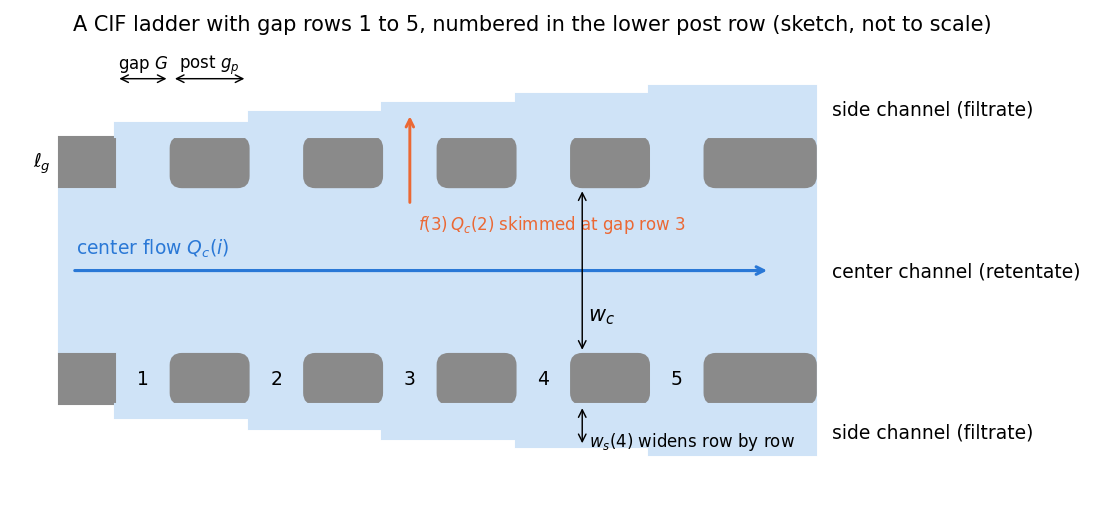

In [5]:
from matplotlib.patches import FancyBboxPatch, Rectangle
fig, ax = plt.subplots(figsize=(11, 3.9))
G, gp, wc, lg = 1.0, 1.4, 3.0, 0.9                  # gap, post (along the flow), center width, post (across the flow)
pitch, x0, nrow = G + gp, 1.0, 5                     # gap row i spans [x0 + (i-1) pitch, x0 + (i-1) pitch + G]
L = x0 + nrow * pitch + 0.6                          # the drawn length
ws = [0.0, 0.25, 0.45, 0.62, 0.78, 0.92]             # side width after row i (exaggerated; zero before row 1 because the start is sealed)
blue, grey = '#cfe3f7', '#8a8a8a'
ax.add_patch(Rectangle((0, -wc / 2), L, wc, color=blue))                       # the center channel
for side in (+1, -1):
    y_wall = side * wc / 2                                                       # the inner edge of the center channel
    y_lo = y_wall if side > 0 else y_wall - lg                                   # the band occupied by the post row
    ax.add_patch(Rectangle((x0, y_lo), L - x0, lg, color=blue))                  # fluid in the gaps
    ax.add_patch(Rectangle((0, y_lo), x0, lg, color=grey))                       # the solid wall upstream of gap 1
    for i in range(nrow):                                                        # a post after each gap
        xp = x0 + i * pitch + G
        ax.add_patch(FancyBboxPatch((xp, y_lo), gp if i < nrow - 1 else L - xp, lg,
                                    boxstyle='round,pad=0,rounding_size=0.2', color=grey))
    for i in range(1, nrow + 1):                                                 # side segment i, which follows row i
        xa = x0 + (i - 1) * pitch
        xb = x0 + i * pitch if i < nrow else L
        y_s = y_wall + side * lg
        ax.add_patch(Rectangle((xa, y_s if side > 0 else y_s - ws[i]), xb - xa, ws[i], color=blue))
for i in range(1, nrow + 1):
    ax.text(x0 + (i - 1) * pitch + G / 2, -wc / 2 - lg / 2, str(i), ha='center', va='center', fontsize=9)
ax.annotate('', xy=(L - 0.8, 0), xytext=(0.2, 0), arrowprops=dict(arrowstyle='->', color='#2a78d6', lw=1.5))
ax.text(0.3, 0.3, 'center flow $Q_c(i)$', color='#2a78d6', fontsize=9)
xg3 = x0 + 2 * pitch + G / 2
ax.annotate('', xy=(xg3, wc / 2 + lg + 0.45), xytext=(xg3, wc / 2 - 0.35),
            arrowprops=dict(arrowstyle='->', color='#eb6834', lw=1.4))
ax.text(xg3 + 0.15, wc / 2 - 0.75, '$f(3)\\,Q_c(2)$ skimmed at gap row 3', color='#eb6834', fontsize=8)
xm = x0 + 3.5 * pitch
ax.annotate('', xy=(xm, wc / 2), xytext=(xm, -wc / 2), arrowprops=dict(arrowstyle='<->', color='k', lw=0.7))
ax.text(xm + 0.1, -0.9, '$w_c$', fontsize=10)
xs = x0 + 3.5 * pitch
ax.annotate('', xy=(xs, -wc / 2 - lg - ws[4]), xytext=(xs, -wc / 2 - lg), arrowprops=dict(arrowstyle='<->', color='k', lw=0.7))
ax.text(xs + 0.12, -wc / 2 - lg - 0.75, '$w_s(4)$ widens row by row', fontsize=8)
ax.annotate('', xy=(x0, wc / 2 + lg + 1.05), xytext=(x0 + G, wc / 2 + lg + 1.05), arrowprops=dict(arrowstyle='<->', color='k', lw=0.7))
ax.text(x0 + G / 2, wc / 2 + lg + 1.25, 'gap $G$', fontsize=8, ha='center')
ax.annotate('', xy=(x0 + G, wc / 2 + lg + 1.05), xytext=(x0 + pitch, wc / 2 + lg + 1.05), arrowprops=dict(arrowstyle='<->', color='k', lw=0.7))
ax.text(x0 + G + gp / 2, wc / 2 + lg + 1.25, 'post $g_p$', fontsize=8, ha='center')
ax.text(-0.15, wc / 2 + lg / 2, '$\\ell_g$', fontsize=9, ha='right', va='center')
ax.text(L + 0.3, wc / 2 + lg + 0.5, 'side channel (filtrate)', fontsize=9, va='center')
ax.text(L + 0.3, 0, 'center channel (retentate)', fontsize=9, va='center')
ax.text(L + 0.3, -wc / 2 - lg - 0.5, 'side channel (filtrate)', fontsize=9, va='center')
ax.set_xlim(-0.8, L + 4.2); ax.set_ylim(-wc / 2 - lg - 1.6, wc / 2 + lg + 1.7); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('A CIF ladder with gap rows 1 to 5, numbered in the lower post row (sketch, not to scale)', fontsize=10)
show(fig, 'fig_2_ladder_sketch')

### 2.1 Symbols

Every entry in the table below is taken from the glossary, from its tables of geometric, fluid and hydraulic,
dimensionless, cutoff-prefactor, particle, and validity-envelope variables, its derivation of the Reynolds number, and
its "Master Cheat-Sheet", and the last column adds the names that the code uses.

| symbol | meaning | unit | the glossary's name or symbol, where it differs | in the code |
|---|---|---|---|---|
| $D$ | cutoff (critical) diameter, above which particles are retained | µm | $d_{\mathrm{crit}}$ (the glossary's $D = 2a$ is a particle's diameter) | `targets.cutoff_um` |
| $F$ | filtrate fraction, the share of the inlet flow that leaves through the side channels | dimensionless | | `targets.filtrate_fraction` |
| $f$, $f(i)$ | per-side, per-gap extraction fraction, the share of the center flow arriving at row $i$ that one gap takes | dimensionless | $f_{\mathrm{gap}}$, $f_{\mathrm{gap}}(i)$ | `plan.f` |
| $g(x)$ | the skim kernel, $g(x) = 3x^2 - 2x^3$ (the glossary reserves lower-case $g$ for the kernel and writes the gap as $G$) | dimensionless | | `kernels.g_cubic` |
| $\delta$ | dividing-streamline (skim) width, the width of the lamina | µm | (the glossary's $w$ is the empirical lamina width) | `plan.delta` |
| $x$ | reduced skim width, $x = \delta/w_c$, the root of $f = 3x^2 - 2x^3$ | dimensionless | | |
| $\tilde d$ | reduced size ratio, $\tilde d = D/w_c$, which sets the plateau ($\tilde d \ge 0.035$) and the foot ($\tilde d < 0.012$) | dimensionless | $\widetilde d = d_{\mathrm{crit}}/w_c$ | `validation.gates.plateau_u_min` (the records call it $u$) |
| $w_c$, $w_c(i)$ | center-channel width, and in a tapered channel the width of segment $i$, after gap row $i$ | µm | | `centre_channel.width_in_um` (and `width_min_um` for a taper) |
| $w_s(i)$ | side-channel width of segment $i$, after gap row $i$ | µm | | planned `plan.ws`; drawn, measured on the mask |
| $h$ | channel depth (every channel) | µm | (Gifford's $d$) | `process.depth_um` |
| $G$ | link width, the along-flow width of the opening in the wall (the gap) | µm | | `process.gap_um` |
| $g_p$ | post width, the along-flow width of the wall segment between two openings | µm | | `process.post_length_um` |
| $\ell_g$ | link length, the wall thickness that the fluid crosses (the post's extent across the flow) | µm | | `process.post_width_um` |
| $\Lambda$ | row pitch, $\Lambda \ge G + g_p$ (equal on the straight rows here), which the glossary treats as a design constraint rather than a definition | µm | | |
| $N$ | total number of gap rows | dimensionless | (Gifford's $i_T$) | `design.N` in the record |
| $i$ | gap row index, $1 \le i \le N$ (flows and segments are labeled $0 \le i \le N$, with 0 the inlet stretch) | dimensionless | | |
| $Q_c(i)$, $Q_s(i)$, $Q_{\mathrm{gap}}(i)$ | volumetric flow in the center channel after gap row $i$, in one side channel after gap $i$, and through one gap on one side at row $i$ | µL/min (nL/min for a gap) | | |
| $P(i)$, $S(i)$ | normalized center and side flows, $P(i) = Q_c(i)/Q_c(0)$ and $S(i) = Q_s(i)/Q_c(0)$ | dimensionless | | `plan.P`, `plan.S` |
| $\sigma(i)$, $\sigma_0$ | cumulative side-flow ratio $\sigma(i) = S(i)/P(i)$, and the fictitious inlet side flow | dimensionless | | |
| $R_c(i)$, $R_s(i)$, $R_{\mathrm{gap}}$ | hydraulic resistance of one center-channel segment, of one side-channel segment, and of one gap | Pa s m⁻³ | | `plan.Rc`, `plan.Rs` |
| $\mu$, $\rho$ | dynamic viscosity and density of the fluid | mPa s; kg m⁻³ | | |
| $\kappa_{\mathrm{app}} \equiv \kappa_g$ | apparent cutoff prefactor, cubic branch, 4.9138 (95% interval 4.75–5.08), a constant on the plateau | dimensionless | | `opencif.physics.kernels.Pairing().kappa` |
| $\kappa_{\mathrm{steric}}$ | steric factor, 2 (a cutoff radius equal to the lamina's width) | dimensionless | | |
| $a$ | particle radius | µm | | |
| $\mathrm{Re}$ | Reynolds number, $\rho U L_{\mathrm{char}}/\mu$, here of the channel | dimensionless | | `validation.gates` |
| $\mathrm{Re}_{\mathrm{gap}}$, $\mathrm{Re}_\delta$ | the design code's Reynolds numbers of the flow through a gap and of the lamina's shear, which its Stokes gate (M14) caps at $10^{-2}$ | dimensionless | | `validation.gates` |
| $\eta$ | realized-yield factor, 0.903, a three-dimensional correction on the flow split (on Dinh's V1, the measured $F$ over the 1-D value) | dimensionless | | `validation.design_code_reports.B6_F_real` (reported, never applied) |
| $F_{\min}$, $\mathrm{AR}_{\max}$ | fabrication limits, the minimum feature (the process floor) and the maximum aspect ratio of a feature | µm; dimensionless | | `process.min_feature_um`, `process.aspect_ratio_max` |

Note that the glossary calls $g_p$, the post's extent along the flow, the "post width", and $\ell_g$, the post's
extent across the flow, the "link length", whereas the YAML keys are `post_length_um` for $g_p$ and `post_width_um`
for $\ell_g$ (`docs/ALIGNMENT.md`, AG5). The two names are easy to confuse, so they are best learned now.

Four further quantities are opencif's usage rather than the glossary's. The design lamina $\delta^* = D/\kappa_g$ is
the lamina that a target cutoff fixes (App. A, Result 13a; `spec.delta_star`), and $f^* = g(\delta^*/w_c)$ is the
per-gap fraction that gives the cutoff at gap 1, whereas the glossary's $f^*_{\mathrm{gap}}$ is Gifford's empirical
threshold, read from data. The realized cutoff $D_i = \kappa_g\,x(f_i)\,w_c(i)$ is the cutoff that gap $i$ gives on
the drawn mask, where $f_i$ is the fraction that the drawn network delivers there (section 6;
`validation.realised_cutoff`). Finally, 'DRC' is the design-rule check, which requires every drawn feature to be at or
above the process floor (`validation.drc`).

## 3. The cutoff axis: from $D$ to the fraction each gap skims

### 3.1 The skim cubic (Appendix A, Result 1)

In laminar flow between two walls, the velocity profile is a parabola. The fraction of the center flow carried by a
layer of width $\delta$ next to one wall is, with $x=\delta/w_c$,

$$ f = 3x^2 - 2x^3 \qquad\text{(App. A, eq. 10)}. $$

The design code `CIF_v2.py` implements this function as `g_cubic`. The kernels of opencif
(`opencif/physics/kernels.py`) restate the design code's formulas, and `tests/test_kernels.py` proves that they return
the same floating-point numbers bit for bit, which the cell below checks again at 201 points. For this comparison the
tutorial imports the design code itself as `C`, whereas the package never imports it. Appendix A defines the cubic for
$0 \le x \le 1$ (eq. 5), whereas opencif's `f_of` accepts only $x < 1/2$, because beyond that value the laminae of the
two walls would meet (App. A, "For implementers", step 3).

def g_cubic(x):
    """Return the fraction of the center channel's flow carried by a lamina of width delta next to one wall, with
    x = delta / w_c. The velocity profile between two walls is a parabola, and its integral across the lamina gives

        f = g(x) = 3 x^2 - 2 x^3                                              (Appendix A, Result 1, eq. 10)

    Thus g(1/2) = 1/2, and half the channel carries half the flow."""
    return 3.0 * x ** 2 - 2.0 * x ** 3

largest |g_cubic(x) - (3x^2 - 2x^3)| on [0, 1/2]: 5.551115123125783e-17
opencif's g_cubic equals the design code's, bit for bit, at all 201 points: True


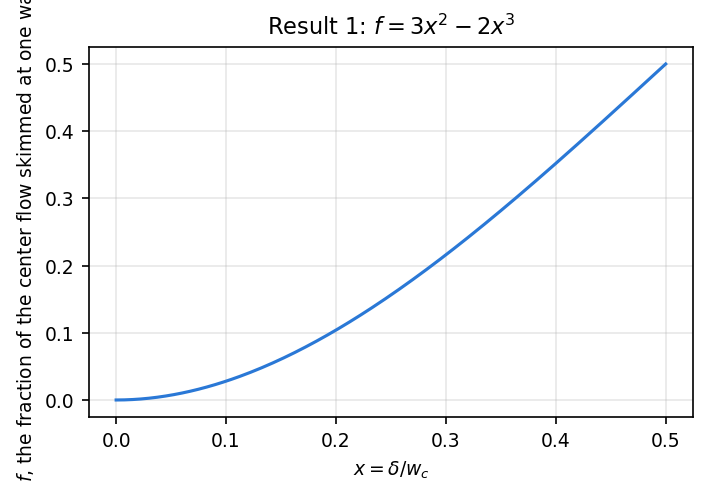

In [6]:
from opencif.physics import schedule as S    # opencif's row schedule
from opencif.physics import kernels as K     # the kernels of Appendix A
sys.path.insert(0, str(TREE / 'reference'))
import CIF_v2 as C                           # the design code, byte-frozen (the package never imports it)
import inspect
print(inspect.getsource(K.g_cubic))          # the kernel, with its derivation cited
x = np.linspace(0, 0.5, 201)
f = np.array([K.g_cubic(v) for v in x])
print('largest |g_cubic(x) - (3x^2 - 2x^3)| on [0, 1/2]:', np.max(np.abs(f - (3 * x**2 - 2 * x**3))))
print('opencif\'s g_cubic equals the design code\'s, bit for bit, at all 201 points:',
      np.array(f).tobytes() == np.array([C.g_cubic(v) for v in x]).tobytes())
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(x, f, color='#2a78d6')
ax.set_xlabel('$x = \\delta / w_c$'); ax.set_ylabel('$f$, the fraction of the center flow skimmed at one wall')
ax.set_title('Result 1: $f = 3x^2 - 2x^3$'); ax.grid(alpha=0.3)
show(fig, 'fig_3_1_skim_cubic')

### 3.2 Inverting the cubic (Appendix A, Result 2)

A gap skims a small fraction of the center flow, $f\sim10^{-4}$. Then $x$ is small, the cubic term is negligible, and
$\delta \approx w_c\sqrt{f/3}$ (the leading law, App. A, eq. 18; App. B, claim C2). opencif uses the exact root of the
cubic, which Viète's formula gives in closed form (App. A, eq. 20) and which `kernels.x_of_f` finds by Brent's method.
The difference between the exact root and the leading law is small over the calibrated range. Appendix B caps the
calibration of the cutoff law at $f \le 5.76\times10^{-4}$ (the glossary's `\fgapDesignCap`), and the alignment matrix
records "exact root vs leading order ≤ 0.47 %" up to that cap (AA6). The cell below prints the difference at three
fractions.

In [7]:
for fv in (1e-5, 1e-4, 5.76e-4):
    xe, xl = S.x_of(fv), math.sqrt(fv / 3)
    print('f = %.2e, exact x = %.6f, leading sqrt(f/3) = %.6f, leading/exact - 1 = %+.3f%%'
          % (fv, xe, xl, 100 * (xl / xe - 1)))

f = 1.00e-05, exact x = 0.001827, leading sqrt(f/3) = 0.001826, leading/exact - 1 = -0.061%
f = 1.00e-04, exact x = 0.005785, leading sqrt(f/3) = 0.005774, leading/exact - 1 = -0.193%
f = 5.76e-04, exact x = 0.013921, leading sqrt(f/3) = 0.013856, leading/exact - 1 = -0.465%


### 3.3 The cutoff law and what $D$ fixes (App. A, Results 5–7 and 13a; App. B, claim C3)

The cutoff is proportional to the lamina, because a particle whose radius exceeds the lamina's width cannot enter it
(the steric argument, App. A, Result 5, with $\kappa_{\mathrm{steric}}=2$). The fitted operating law is

$$ d_{\mathrm{crit}} = \kappa_{\mathrm{app}}\,\delta, \qquad \delta \approx w_c\sqrt{f/3} \ \text{at leading order (section 3.2)}, $$

and opencif evaluates $\delta$ with the exact root of the cubic rather than with the leading law. Appendix B (claim
C3b) fits the plateau prefactor $\kappa_{\mathrm{app}} = 4.91$ [4.75, 5.08] on Gifford's calibration data, and the
glossary's cubic-branch value is $\kappa_g = 4.9138$. Measured cutoffs are about 2.5 times the steric value
($\kappa_{\mathrm{app}}/\kappa_{\mathrm{steric}} = 2.4569$), which Appendix A attributes to the finite depth, to a
per-gap over-extraction, and to finite-particle effects (Result 5, "From the steric value to the measured
prefactor"). In other words, the steric picture fixes the scaling, the calibration fixes the prefactor, and opencif
uses the measured $\kappa_g$. The 'pairing rule' (App. A, Result 9; glossary, "Cutoff-Law Prefactor Decomposition")
states that a prefactor goes with the kernel it was fitted with, and accordingly opencif uses the cubic kernel with
$\kappa_g$ at every call site (AA13).

Thus, a target cutoff fixes the lamina once, $\delta^* = D/\kappa_g$, and the fraction at every row is
$f(i) = g\!\left(\delta^*/w_c(i)\right)$. This is the 'invariant-lamina schedule' (App. A, Result 13a; the design
code's S1). For a constant center width, every row skims the same fraction, whereas a narrower center channel must
skim more to keep the same lamina, since $f \propto w_c^{-2}$ at leading order (Result 7).

kappa_g = 4.9138 (95% interval 4.75 to 5.08; App. B, C3b, prints [4.75, 5.08])
D = 4.0 um, so the lamina is delta* = D / kappa_g = 0.8140 um
  w_c =  60 um: f = g(delta*/w_c) = 5.472e-04,  reduced size ratio D/w_c = 0.0667
  w_c =  80 um: f = g(delta*/w_c) = 3.085e-04,  reduced size ratio D/w_c = 0.0500
  w_c = 100 um: f = g(delta*/w_c) = 1.977e-04,  reduced size ratio D/w_c = 0.0400


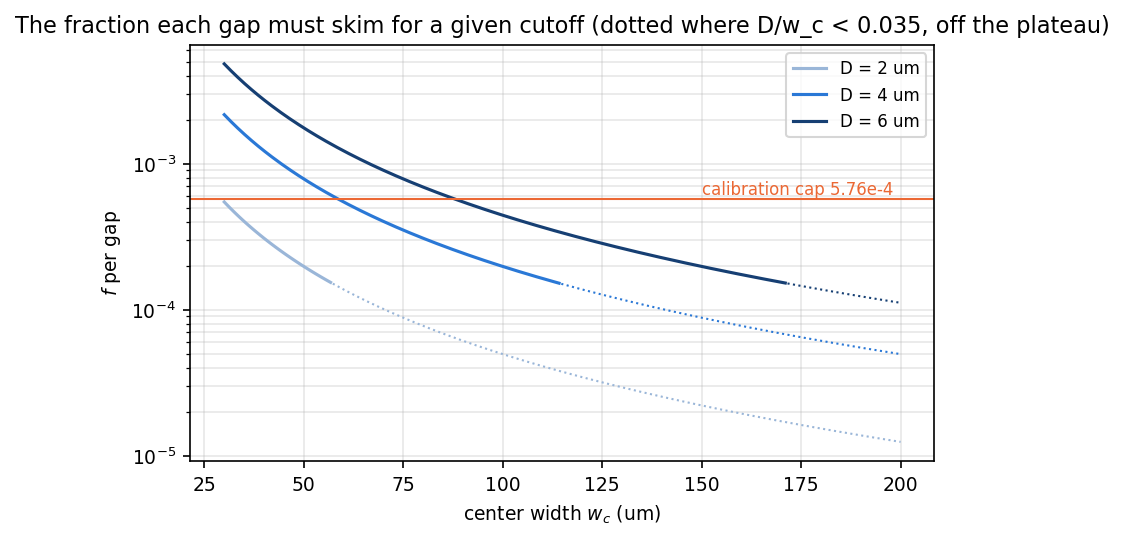

In [8]:
print('kappa_g = %.4f (95%% interval %.2f to %.2f; App. B, C3b, prints [4.75, 5.08])' % (S.KAPPA_G, *S.KAPPA_CI))
D = 4.0
dstar = D / S.KAPPA_G
print('D = %.1f um, so the lamina is delta* = D / kappa_g = %.4f um' % (D, dstar))
for wc in (60, 80, 100):
    print('  w_c = %3d um: f = g(delta*/w_c) = %.3e,  reduced size ratio D/w_c = %.4f' % (wc, S.f_of(dstar, wc), D / wc))

wcs = np.linspace(30, 200, 300)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for Dv, col in ((2.0, '#9ab6d8'), (4.0, '#2a78d6'), (6.0, '#163f73')):
    ok = Dv / wcs >= 0.035                           # on the kappa plateau
    fv = np.array([S.f_of(Dv / S.KAPPA_G, w) for w in wcs])
    ax.plot(wcs[ok], fv[ok], color=col, label='D = %g um' % Dv)
    ax.plot(wcs[~ok], fv[~ok], color=col, ls=':', lw=1)
ax.axhline(5.76e-4, color='#eb6834', lw=1)
ax.text(150, 6.2e-4, 'calibration cap 5.76e-4', color='#eb6834', fontsize=8)
ax.set_yscale('log'); ax.set_xlabel('center width $w_c$ (um)'); ax.set_ylabel('$f$ per gap')
ax.set_title('The fraction each gap must skim for a given cutoff (dotted where D/w_c < 0.035, off the plateau)')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
show(fig, 'fig_3_3_f_per_gap')

### 3.4 Where the law holds: the plateau and the calibration cap

The prefactor $\kappa_{\mathrm{app}}$ is a constant only on the 'plateau', $\tilde d = d_{\mathrm{crit}}/w_c \gtrsim
0.035$ (the glossary's `\plateauUwc`; App. B, Notation and C3c). Below the plateau edge, the prefactor depends on
$\tilde d$ and the cutoff law becomes implicit. The prefactor falls through a knee near $\tilde d \approx 0.03$ to a
sub-steric 'foot', that is, a prefactor below the steric value of 2, with $\kappa_{\mathrm{app}} \approx 1.34$ for
$\tilde d < 0.012$ (the mean of three 1 µm-bead points, which lie outside the regime that the dissertation's claims
cover). Below the plateau edge, opencif reports a cutoff band instead of a single cutoff, and below the foot it reports
none. The band comes from a Hill curve, which is a smooth S-shaped fit of $\kappa_{\mathrm{app}}$ against $\tilde d$
through the knee. The band runs from $\kappa_{\mathrm{app}}(u)\,\delta^*$, with $u = \kappa_g\delta^*/w_c$, up to the
plateau value $\kappa_g\delta^*$, and Appendix B records that such a band is read off the plateau anchor rather than
being the device's self-consistent cutoff (App. B, claim C7, P-C7.1 and CQ3; `docs/ALIGNMENT.md`, AB5). Therefore, for a
given $D$ the center channel may be at most $D/0.035$ wide, and the default of `opencif.generate`, $w_c = D/0.05$, lies
inside the plateau. Furthermore, $\kappa_g$ was fitted on gaps that skim at most $5.76\times10^{-4}$ of the center flow,
so a design above that cap is reported rather than refused (AG12). Section 8 shows what the generator does when a design
leaves the plateau.

## 4. The yield axis: from $F$ to the number of rows, and from flows to widths

### 4.1 The march (Appendix A, Result 10)

Number the gap rows $i=1, \dots, N$ and divide every flow by the inlet center flow, so that $P(i)$ is the center flow
after row $i$ and $S(i)$ is the flow in one side channel. At row $i$, each side gap takes $f(i)P(i-1)$, so

$$ P(i) = \big(1-2f(i)\big)P(i-1), \qquad S(i) = S(i-1) + f(i)P(i-1), \qquad P(0)=1,\ S(0)=\sigma_0 . $$

With a sealed inlet, in which all of the fluid enters the center channel, $\sigma_0=0$. Mass is conserved, so
$P(i)+2S(i) = 1+2\sigma_0$ (the 'mass identity'). The filtrate fraction is the share of the flow that has left the
center channel,

$$ F = 1-P(N) = 1-\prod_{i=1}^{N}\big(1-2f(i)\big) \qquad\text{(App. A, eq. 67; the glossary's } F_{\mathrm{recursion}}\text{)}. $$

These relations are the entire march. In the example that Appendix A gives for implementers, $f=10^{-4}$ at every row
for 5,000 rows yields $P = 0.367843$, $\sigma = S/P = 0.859277$, and $F = 0.632157$ (AA14), which the cell below
reproduces.

In [9]:
def march(f_rows, sigma0=0.0):
    P, Sd = 1.0, sigma0
    Ps, Ss = [], []
    for fi in f_rows:
        P, Sd = (1 - 2 * fi) * P, Sd + fi * P        # the right-hand side uses the old P
        Ps.append(P); Ss.append(Sd)
    return np.array(Ps), np.array(Ss)

P, Sd = march([1e-4] * 5000)
print('after 5000 rows, P = %.6f, sigma = S/P = %.6f, and F = 1 - P = %.6f' % (P[-1], Sd[-1] / P[-1], 1 - P[-1]))
print('largest violation of the mass identity P + 2S = 1:', np.max(np.abs(P + 2 * Sd - 1)))

after 5000 rows, P = 0.367843, sigma = S/P = 0.859277, and F = 1 - P = 0.632157
largest violation of the mass identity P + 2S = 1: 7.061018436615996e-14


### 4.2 The number of rows (App. A, Result 10, "Row count")

For a constant fraction, $F = 1-(1-2f)^N$, so $N = \ln(1-F)/\ln(1-2f)$, rounded up to the next integer. In the example
of Appendix A, $F = 0.5$ at $f = 1.04\times10^{-4}$ requires 3,332.1 rows, so 3,333 rows are needed.

In [10]:
Nc = math.log(1 - 0.5) / math.log(1 - 2 * 1.04e-4)
print('N = ln(1 - F) / ln(1 - 2f) = %.1f, so %d rows' % (Nc, math.ceil(Nc)))

N = ln(1 - F) / ln(1 - 2f) = 3332.1, so 3333 rows


### 4.3 The design map: $D$ fixes the lamina and $F$ fixes $N$ (App. A, Result 13; App. B, claim C8)

Because the cutoff fixes $\delta^*$, and with it every $f(i)$, the filtrate target can be met only through the number
of rows. The Jacobian of the map $(\delta^*, N)\mapsto(d_{\mathrm{crit}}, F)$ is lower-triangular, which means that on
the plateau a change in $N$ does not move the cutoff (Result 13c). Furthermore, since each row skims a fraction
proportional to $\delta^{*2}$, the product $N D^2$ is nearly constant at a fixed $F$ and channel shape, so halving the
cutoff quadruples the number of rows (Result 13b).

The cell below asks the generator to plan nine devices for three cutoffs and three filtrate fractions, using the parts
of `examples/decoupling/` (a straight leg with $w_c$ = 80 µm, a packed meander head, a depth of 100 µm, and 19 µm
gaps). With `check_only='plan'`, the generator plans the device and evaluates the gates without drawing it, which
takes seconds per design.

 D (um)  F target   N     F planned   D planned  exit
  3.0     0.3     1026    0.30007     3.0000     0
  3.0     0.5     1994    0.50011     3.0000     0
  3.0     0.7     3463    0.70006     3.0000     0
  4.0     0.3      578    0.30005     4.0000     0
  4.0     0.5     1124    0.50030     4.0000     0
  4.0     0.7     1951    0.70006     4.0000     0
  5.0     0.3      371    0.30040     5.0000     0
  5.0     0.5      720    0.50008     5.0000     0
  5.0     0.7     1251    0.70019     5.0000     0
F = 0.3: N D^2 = 9234, 9248, 9275 (spread 0.44%)
F = 0.5: N D^2 = 17946, 17984, 18000 (spread 0.30%)
F = 0.7: N D^2 = 31167, 31216, 31275 (spread 0.35%)


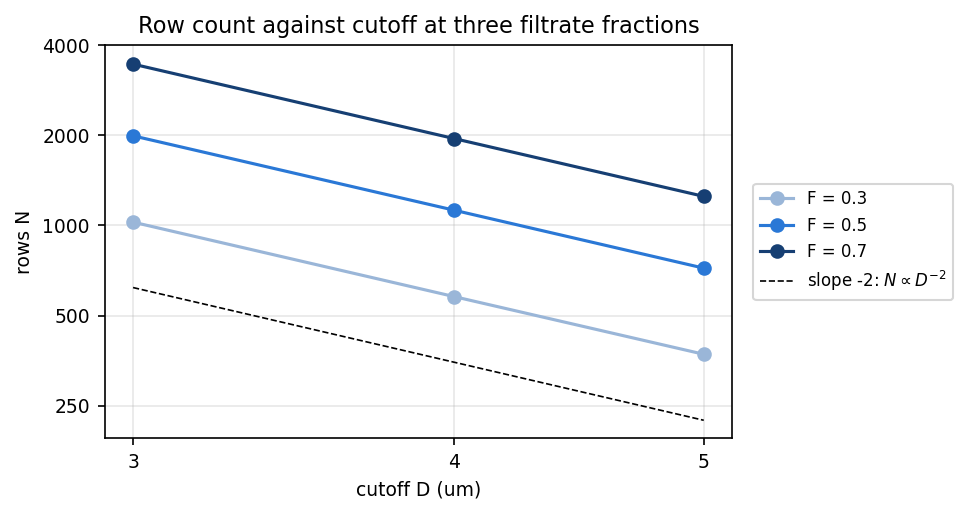

In [11]:
DC = dict(process=dict(depth_um=100, gap_um=19, post_length_um=27, post_width_um=50, min_feature_um=19),
          layout='linear', taper=('constant', 80),
          meander=dict(style='pack', channel_um=28, wall_um=27, head_width_um=4000, seal='require'),
          inlet=dict(style='plain', port_radius_um=750),
          outlet=dict(style='separate', port_radius_um=750, centre_port_radius_um=750))
rows = []
for Dv in (3.0, 4.0, 5.0):
    for Fv in (0.3, 0.5, 0.7):
        r = opencif.generate(Dv, Fv, out=OUT / 'plans', check_only='plan', name='dc_D%g_F%g' % (Dv, Fv), **DC)
        d = r.record['design']
        rows.append((Dv, Fv, d['N'], d['F_planned'], d['D_um'], r.exit_code))
print(' D (um)  F target   N     F planned   D planned  exit')
for Dv, Fv, N, Fp, Dp, ec in rows:
    print('  %.1f     %.1f    %5d    %.5f     %.4f     %d' % (Dv, Fv, N, Fp, Dp, ec))
for Fv in (0.3, 0.5, 0.7):
    nd = [N * Dv**2 for Dv, F_, N, *_ in rows if F_ == Fv]
    print('F = %.1f: N D^2 = %s (spread %.2f%%)' % (Fv, ', '.join('%.0f' % v for v in nd), 100 * (max(nd) / min(nd) - 1)))
fig, ax = plt.subplots(figsize=(5.4, 3.4))
for Fv, col in ((0.3, '#9ab6d8'), (0.5, '#2a78d6'), (0.7, '#163f73')):
    Ds = [Dv for Dv, F_, *_ in rows if F_ == Fv]; Ns = [N for Dv, F_, N, *_ in rows if F_ == Fv]
    ax.loglog(Ds, Ns, 'o-', color=col, label='F = %.1f' % Fv)
ax.loglog([3, 5], [620, 620 * (3 / 5) ** 2], 'k--', lw=0.8, label='slope -2: $N \\propto D^{-2}$')
ax.set_xticks([3, 4, 5]); ax.set_xticklabels(['3', '4', '5']); ax.minorticks_off()
ax.set_yticks([250, 500, 1000, 2000, 4000]); ax.set_yticklabels(['250', '500', '1000', '2000', '4000'])
ax.set_xlabel('cutoff D (um)'); ax.set_ylabel('rows N'); ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5))
ax.set_title('Row count against cutoff at three filtrate fractions')
show(fig, 'fig_4_3_decoupling')

Every plan sets its lamina from its own $D$ ($\delta^* = D/\kappa_g$, so the planned $D$ equals the target by
construction) and meets its $F$ to within one row's extraction. The product $N D^2$ is constant to about half a
percent at each $F$ (App. B, P-C8.2, reports the same invariance, and the alignment matrix records 0.51% for the cubic
pair over $D$ = 3 to 7 µm, AA23). What a drawing realizes is checked by building it. In the release's own builds of
`examples/decoupling/` (`validation/RELEASE.json` lists all nine, each with exit 0 and a passing physics audit), each
drawn mask realizes its own $D$ within ±1% at every gap (Q2, section 6) and its own $F$.

### 4.4 From flows to widths: the closure (App. A, Result 10, eq. 69; Result 14)

The march gives flows, whereas a photomask needs widths. Gifford's assumption, 'pressure equilibration' (PE), is that
each gap row equalizes the pressure across the device, so that within one stretch the side and center segments see the
same pressure drop and carry flows in the ratio of their conductances,

$$ \sigma(i) = \frac{S(i)}{P(i)} = \frac{R_c(i)}{R_s(i)} \qquad\text{(App. A, eq. 69)}. $$

Here $R$ is the resistance of a rectangular duct (App. A, Result 14, which is Gifford's eqn 5, the Yang series; `r` in
the design code, `kernels.r` in opencif, and `schedule.rr` for widths in micrometers). At a fixed depth, the resistance
strictly decreases as the width grows (Result 14, "Monotonicity"), so each $R_s(i)$ corresponds to exactly one side
width, which a one-dimensional search finds. Gifford increased $w_s$ step by step until the resistance matched,
whereas the cell below uses Brent's method.

opencif does not assume PE. Its 'exact gap-drop closure' (design specification v5, section 13) keeps the pressure
drop across each gap, and it reduces to the PE closure when the resistance of the gaps is negligible
(`docs/ALIGNMENT.md`, AA17, "GENERALISED"). The cell below plans the straight Gifford-style example
`examples/gifford_physics_linear.yaml` and compares opencif's side widths with the PE closure, which we compute here
from opencif's own $P(i)$ and $S(i)$.

plan: N = 1814 rows, F = 0.80017, w_c = 100 um, h = 80 um, delta* = 1.2211 um (D = 6.00 um)
square duct: R h^4 / (mu L) = 28.4542 (App. A, Result 14, gives 28.4542)


opencif w_s(1), w_s(N-1): 5.347, 153.212 um; PE closure: 5.347, 153.208 um
largest relative difference between the exact gap-drop closure and the PE closure: 2.5e-05


gap dominance M13 = 0.0407 (gate 0.05); R_s(exact) / R_s(PE) - 1 = -3.6178e-05 (median over the rows; -3.6178e-05 to -3.6178e-05); -2 f M13 = -3.6146e-05


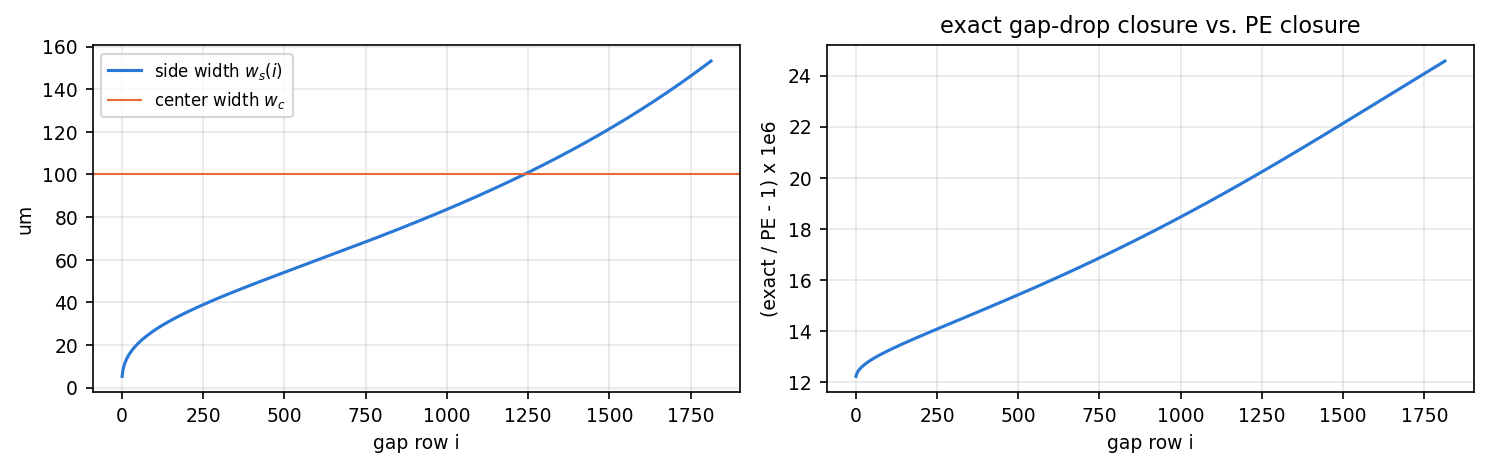

In [12]:
from opencif import spec as SP
from scipy.optimize import brentq
d_lin = SP.load(str(TREE / 'examples' / 'gifford_physics_linear.yaml'))
sp = SP.to_engine(d_lin)[0]
plan = S.plan(sp)
print('plan: N = %d rows, F = %.5f, w_c = %.0f um, h = %.0f um, delta* = %.4f um (D = %.2f um)'
      % (plan.N, plan.F, sp.wc0, sp.h, sp.delta_star, S.KAPPA_G * sp.delta_star))
print('square duct: R h^4 / (mu L) = %.4f (App. A, Result 14, gives 28.4542)' % (S.rr(20.0, 20.0) * (20.0 * S.UM) ** 4 / S.MU))
seg = np.arange(plan.N - 1)                          # segments 1 to N-1, between the rows; the last segment is the outlet stretch
w_pe = np.array([brentq(lambda w: S.rr(w, sp.h) - S.rr(plan.wc[i], sp.h) * plan.P[i] / plan.S[i], 1e-3, 5e3) for i in seg])
rel = plan.ws[seg] / w_pe - 1
print('opencif w_s(1), w_s(N-1): %.3f, %.3f um; PE closure: %.3f, %.3f um' % (plan.ws[0], plan.ws[seg[-1]], w_pe[0], w_pe[-1]))
print('largest relative difference between the exact gap-drop closure and the PE closure: %.1e' % np.max(np.abs(rel)))
S.clear_caches()
g_lin = PL.prepare(SP.load(str(TREE / 'examples' / 'gifford_physics_linear.yaml')), lambda m: None)[3]
m13, f_row = g_lin['M13_gap_dominance_max'], plan.f[5]
rs_rel = plan.Rs[seg] / (plan.Rc[seg] * plan.P[seg] / plan.S[seg]) - 1
print('gap dominance M13 = %.4f (gate 0.05); R_s(exact) / R_s(PE) - 1 = %.4e (median over the rows; %.4e to %.4e); '
      '-2 f M13 = %.4e' % (m13, np.median(rs_rel), rs_rel.min(), rs_rel.max(), -2 * f_row * m13))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(seg + 1, plan.ws[seg], color='#2a78d6', label='side width $w_s(i)$')
ax[0].axhline(sp.wc0, color='#eb6834', lw=1, label='center width $w_c$')
ax[0].set_xlabel('gap row i'); ax[0].set_ylabel('um'); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].plot(seg + 1, 1e6 * rel, color='#2a78d6')
ax[1].set_xlabel('gap row i'); ax[1].set_ylabel('(exact / PE - 1) x 1e6'); ax[1].grid(alpha=0.3)
ax[1].set_title('exact gap-drop closure vs. PE closure')
plt.tight_layout(); show(fig, 'fig_4_4_closure')

The two closures agree to a few parts in $10^5$ on this device, even though the resistance of the gaps is far from
negligible, since the gap-dominance number (the design code's M13, $R_{\mathrm{gap}} f / R_c$) is 0.041, close to its
0.05 gate. The agreement arises because the exact closure differs from PE only by the change in the gap's pressure
drop from one row to the next (spec v5, section 13, gives
$R_c Q_c - R_s Q_s = R_{\mathrm{gap}}Q_{\mathrm{gap}}(i) - R_{\mathrm{gap}}Q_{\mathrm{gap}}(i+1)$). With a constant
$f$, that change is $2f^2$ of the center flow, so $R_s$ moves by $2f\,\mathrm{M13} \approx 4\times10^{-5}$, as printed
above. Exercise 4 repeats the comparison on a tapered device, on which $f$ changes from row to row.

Note that the first side channel is only a few micrometers wide, because a sealed start asks for a first side width
near zero (App. A, Result 10, "Row-1 closure", $R_s(1)\approx R_c/f$). Printing such a channel requires a fine
process. This example assumes a 4.5 µm floor and a 25:1 aspect-ratio limit (its 5.3 µm side channel is 80 µm deep,
15:1, whereas opencif's default limit is 10:1; `docs/ALIGNMENT.md`, AG7c), which is a stated capability rather than a
foundry fact. On a 19 µm process, the generator draws a meander head instead (section 6).

### 4.5 Gifford's Fig. 2 from the planner

Gifford et al. (2014) show the design family of the straight device in their Fig. 2. Panel A gives the side-channel
width $w_s(i)$ against the row number for six values of $f_{\mathrm{gap}}$ at a depth of 100 µm, panel B gives the
ratio of the side flow to the center flow, $Q_s(i)/Q_c(i)$, for the same six values, panel C gives $w_s(i)$ at
$f_{\mathrm{gap}} = 1.76\times10^{-4}$ for six depths from 150 µm down to 5 µm, and panel D gives the flow ratio for
those six depths. The paper states that
"each curve in Fig. 2 was generated using only eqn (4) and (5), with the initial side channel width, ws(0), set to zero"
(p. 4499), that is, from the PE closure and the duct law alone, and the caption gives the endpoint of every curve as
"ws(i) = wc = 100 μm". At that endpoint $R_s = R_c$, so $\sigma = 1$ and $F = 2\sigma/(1+2\sigma) = 2/3$. Note that
the glossary writes $f_{\mathrm{gap}}$ for the tutorial's $f$ and $N$ for Gifford's $i_T$, "the necessary total
number of rows of gaps", which for a constant fraction is $i_T = \ln 3/[-\ln(1 - 2 f_{\mathrm{gap}})]$.

Both the panel's own label and the caption print the largest of the six values as $5.76 \times 10^{-3}$. The figure
itself shows that the exponent is a misprint, because the steepest curve of panel A ends near row 950, which is the
$i_T$ of $5.76 \times 10^{-4}$ (953), whereas $5.76 \times 10^{-3}$ would end at row 95. The six values are therefore
$k \times 9.6 \times 10^{-5}$ for $k$ = 6 down to 1, which decrease linearly from $5.76 \times 10^{-4}$, the largest
$f_{\mathrm{gap}}$ of Gifford's calibration array (p. 4500), to the caption's $9.6 \times 10^{-5}$.

The cell below reproduces the four panels with opencif's planner. Each plan asks for $F = 2/3$ and for the cutoff that
$f_{\mathrm{gap}}$ implies at $w_c$ = 100 µm, $D = \kappa_g\, x(f_{\mathrm{gap}})\, w_c$, which inverts section 3.3,
so that the planner's constant $f(i)$ equals $f_{\mathrm{gap}}$. The process floor and the aspect-ratio limit are set
far below the first side width, because the curves are hydraulics alone, and the gap's entrance term is set to zero,
because Gifford's eqn (4) contains no gap resistance. The resistance of the gap's passage through the wall remains, so
the widths are those of opencif's exact gap-drop closure, which differs from the PE closure by the few parts in
$10^5$ that section 4.4 measured. Three checks follow. The planner's $N$ equals Gifford's $i_T$ rounded up, its
flow ratio equals the closed form $\sigma(i) = [(1 - 2 f_{\mathrm{gap}})^{-i} - 1]/2$ that the march gives for a
constant $f$, and the six curves of panel D coincide because the march never sees the depth (Result 10), whereas the
widths of panel C fan out because the duct law does (Result 14). The design code's validator M19 makes the same three
checks on its own engine (section 11), and `tests/test_design_code.py`, section 6, makes them on opencif's planner.

twelve plans in 12 s
panels A and B, at a depth of 100 um
    f_gap      N      i_T    largest |f(i)/f_gap - 1|   largest |sigma(i) - closed form|   w_s(N-1) (um)
  5.76e-04    954    953.1         3.3e-16                     3.7e-14                   99.99
  4.80e-04   1144   1143.8         2.2e-16                     4.1e-14                   99.94
  3.84e-04   1430   1429.9         6.7e-16                     1.1e-14                   99.95
  2.88e-04   1907   1906.8         0.0e+00                     3.5e-14                   99.97
  1.92e-04   2861   2860.4         3.3e-16                     1.4e-13                   99.99
  9.60e-05   5722   5721.4         2.2e-16                     1.5e-13                   99.99
panels C and D, at f_gap = 1.76e-04, give N = 3121 at all six depths, and their flow-ratio curves differ by at most 0.0e+00
the side width at row 1000 is 54.4 um at a depth of 150 um and 23.6 um at 5 um
the published curves of panel A end near rows 951, 1143, 1426, 1

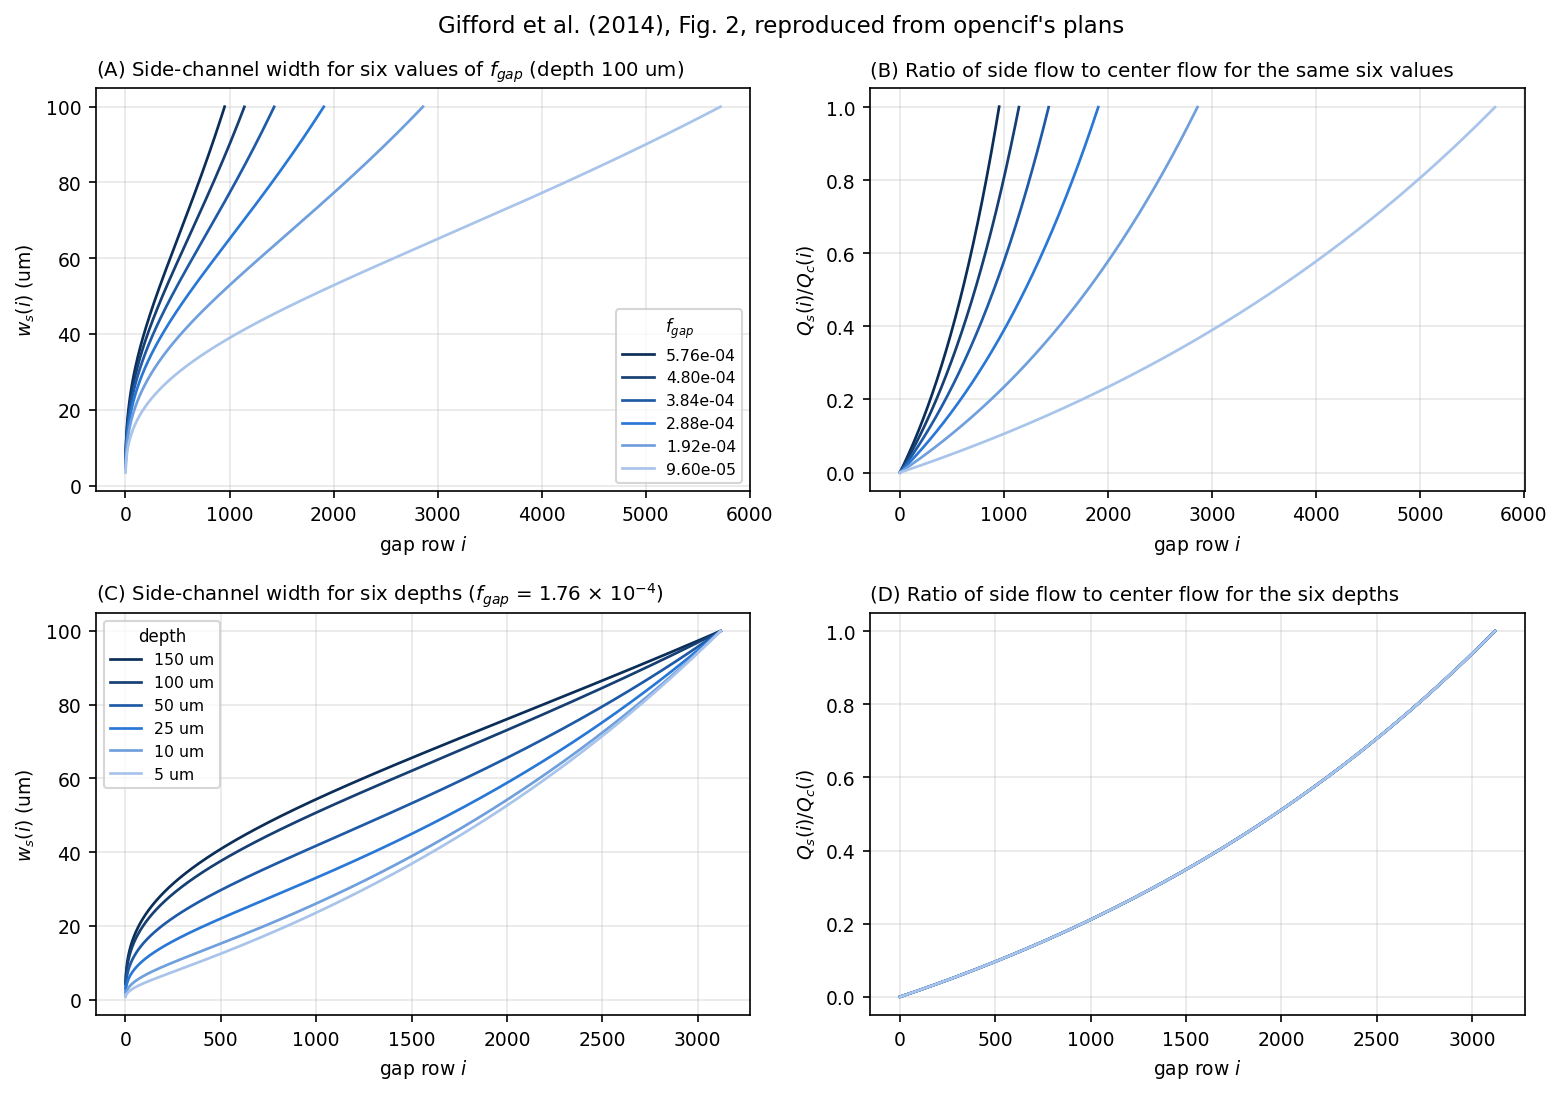

In [13]:
# Gifford et al. (2014), Fig. 2, from opencif's planner. Panels A and B use six constant fractions at a depth of 100 um,
# and panels C and D use f_gap = 1.76e-4 at six depths. Each plan asks for F = 2/3, the paper's endpoint w_s = w_c, and
# for the cutoff that f_gap implies at w_c = 100 um, so that the planner's constant f(i) equals f_gap. The process
# floor and the aspect-ratio limit lie far below the first side width, because the curves are hydraulics alone, and
# the gap's entrance term is zero, because Gifford's eqn (4) contains no gap resistance.
WC_G = 100.0
F_AB = [k * 9.6e-5 for k in (6, 5, 4, 3, 2, 1)]                   # the caption's six values, in equal steps
H_CD = [150.0, 100.0, 50.0, 25.0, 10.0, 5.0]
F_CD = 1.76e-4


def fig2_plan(f, h):
    D = S.KAPPA_G * S.x_of(f) * WC_G                                # the cutoff that f implies (section 3.3, inverted)
    d = opencif.build_spec(D, 2.0 / 3.0, process=dict(depth_um=h, gap_um=20.5, post_length_um=25.6,
                                                      post_width_um=50.6, min_feature_um=0.2,
                                                      aspect_ratio_max=5000.0, gap_entrance_c=0.0),
                           width_in_um=WC_G, meander=None, mode='evaluate', name='fig2')
    S.clear_caches()
    pl = S.plan(SP.to_engine(SP.load(d))[0])
    i = np.arange(1, pl.N + 1, dtype=float)
    return dict(N=pl.N, iT=math.log(3.0) / -math.log(1.0 - 2.0 * f), i=i, sigma=pl.S / pl.P,
                closed=((1.0 - 2.0 * f) ** (-i) - 1.0) / 2.0, ws=pl.ws[:pl.N - 1],
                f_dev=float(np.max(np.abs(pl.f / f - 1.0))))


t0 = time.time()
AB = [fig2_plan(f, 100.0) for f in F_AB]
CD = [fig2_plan(F_CD, h) for h in H_CD]
print('twelve plans in %.0f s' % (time.time() - t0))
print('panels A and B, at a depth of 100 um')
print('    f_gap      N      i_T    largest |f(i)/f_gap - 1|   largest |sigma(i) - closed form|   w_s(N-1) (um)')
for f, g in zip(F_AB, AB):
    print('  %.2e  %5d  %7.1f         %.1e                     %.1e                  %6.2f'
          % (f, g['N'], g['iT'], g['f_dev'], float(np.max(np.abs(g['sigma'] - g['closed']))), g['ws'][-1]))
spread = max(float(np.max(np.abs(g['sigma'] - CD[0]['sigma']))) for g in CD)
print('panels C and D, at f_gap = %.2e, give N = %s at all six depths, and their flow-ratio curves differ by at '
      'most %.1e' % (F_CD, ', '.join(str(n) for n in sorted({g['N'] for g in CD})), spread))
print('the side width at row 1000 is %.1f um at a depth of 150 um and %.1f um at 5 um'
      % (CD[0]['ws'][999], CD[-1]['ws'][999]))
# The rows at which the six curves of the published panel A end, read from the figure (tests/test_design_code.py,
# section 6, gives the method).
DIGITIZED = [951, 1143, 1426, 1898, 2840, 5627]
print('the published curves of panel A end near rows %s, and the plans end at rows %s'
      % (', '.join(map(str, DIGITIZED)), ', '.join(str(g['N']) for g in AB)))

blues = ['#0b2e59', '#163f73', '#1f5aa6', '#2a78d6', '#6f9fdc', '#a9c4ea']
fig, ax = plt.subplots(2, 2, figsize=(10.5, 7.4))
for g, f, c in zip(AB, F_AB, blues):
    ax[0, 0].plot(g['i'][:-1], g['ws'], color=c, lw=1.3, label='%.2e' % f)
    ax[0, 1].plot(g['i'], g['sigma'], color=c, lw=1.3)
for g, h, c in zip(CD, H_CD, blues):
    ax[1, 0].plot(g['i'][:-1], g['ws'], color=c, lw=1.3, label='%g um' % h)
    ax[1, 1].plot(g['i'], g['sigma'], color=c, lw=1.3)
ax[0, 0].set_title('(A) Side-channel width for six values of $f_{gap}$ (depth 100 um)', fontsize=9.5, loc='left')
ax[0, 1].set_title('(B) Ratio of side flow to center flow for the same six values', fontsize=9.5, loc='left')
ax[1, 0].set_title('(C) Side-channel width for six depths ($f_{gap}$ = 1.76 × 10$^{-4}$)', fontsize=9.5, loc='left')
ax[1, 1].set_title('(D) Ratio of side flow to center flow for the six depths', fontsize=9.5, loc='left')
ax[0, 0].legend(title='$f_{gap}$', fontsize=7.5, title_fontsize=8)
ax[1, 0].legend(title='depth', fontsize=7.5, title_fontsize=8)
for a in ax.flat:
    a.set_xlabel('gap row $i$')
    a.grid(alpha=0.3)
for a in ax[:, 0]:
    a.set_ylabel('$w_s(i)$ (um)')
for a in ax[:, 1]:
    a.set_ylabel('$Q_s(i)/Q_c(i)$')
fig.suptitle("Gifford et al. (2014), Fig. 2, reproduced from opencif's plans", fontsize=11)
plt.tight_layout()
show(fig, 'fig_4_5_gifford_fig2')

The plans end at the rows of the closed form, and the six values $k \times 9.6 \times 10^{-5}$ end within 2% of the
curves digitized from the published figure, which the cell prints beside the planned rows. The design code's own list
in `CIF_v2.gifford_fig2`, $(5.76, 4.83, 3.90, 2.97, 2.04, 0.96) \times 10^{-4}$, does not follow the caption's linear
sequence and ends 5% early on the fifth curve, and `tests/test_design_code.py`, section 6, makes both comparisons. The
paper's curves end slightly before the closed form, and the slowest of them ends 1% to 2% early (1.7%, against 0.7%
for the next one); the cause is not established. The published figure is not reproduced in this repository, and only
the rows read from it are.

## 5. The whole path in fewer than 300 lines: a straight ladder by hand

The module `opencif/teaching.py` follows, for the simplest device, the generator's whole path from $(D, F)$ to an
audited photomask. It takes the steps of sections 3 and 4 ($\delta^* = D/\kappa_g$, the fraction $f$, the march, the
resistances, the closure, and the widths), then draws the device, writes the photomask, and audits the photomask with a
reader that knows nothing of the design. The device is a straight ladder with a constant center width and a sealed inlet
(the example of section 4.4). The module is short enough to read in one sitting, and each step is named after the result
of Appendix A that it uses. The cell below runs its design step and compares the result with the generator's plan of the
same device.

In [14]:
from opencif import teaching as T
print('opencif/teaching.py: %d lines' % open(TREE / 'opencif' / 'teaching.py').read().count('\n'))
p_ = d_lin['process']
lad = T.design(D_um=d_lin['targets']['cutoff_um'], F=d_lin['targets']['filtrate_fraction'], depth_um=p_['depth_um'],
               gap_um=p_['gap_um'], post_um=p_['post_length_um'], wall_um=p_['post_width_um'],
               centre_um=d_lin['centre_channel']['width_in_um'], outlet_um=sp.L_out)
print('teaching.design: N = %d rows, f = %.4e at every row, w_s from %.3f to %.3f um, and F = %.6f'
      % (lad.N, lad.f, lad.ws[0], lad.ws[-1], lad.F))
same = (lad.N == plan.N and np.array_equal(lad.P, plan.P) and np.array_equal(lad.S, plan.S)
        and np.array_equal(lad.Rs, plan.Rs) and np.array_equal(lad.ws, plan.ws[:plan.N - 1]))
print('the same march, closure, and side widths as the generator\'s plan, number for number:', same)

opencif/teaching.py: 297 lines


teaching.design: N = 1814 rows, f = 4.4365e-04 at every row, w_s from 5.347 to 153.212 um, and F = 0.800167
the same march, closure, and side widths as the generator's plan, number for number: True


Next, a smaller ladder ($F$ = 0.3, so about 400 rows) is drawn, written as a photomask, and read back. The audit finds
the posts (the ISLANDS layer of the file), the gaps (the openings along a line through the middle of each wall), and
the center and side widths (cuts across the channels). It then computes every resistance (App. A, Result 14), solves
the flow network of the drawn device (Kirchhoff's laws), and reports each gap's realized cutoff
$D_i = \kappa_g\,x(f_i)\,w_c$ and the filtrate fraction. The depth cannot be seen on a mask, so it is the one input.

the photomask has 402 gaps and 401 posts per side; read back, the wall is 59.50 um, the gaps 20.500 to 20.500 um, and the center 100.000 to 100.000 um
realized cutoff at every gap 6.000000 to 6.000000 um (D = 6 um; largest relative deviation 5.1e-11)
filtrate fraction on the drawn mask 0.300124 (the design gives 0.300124)


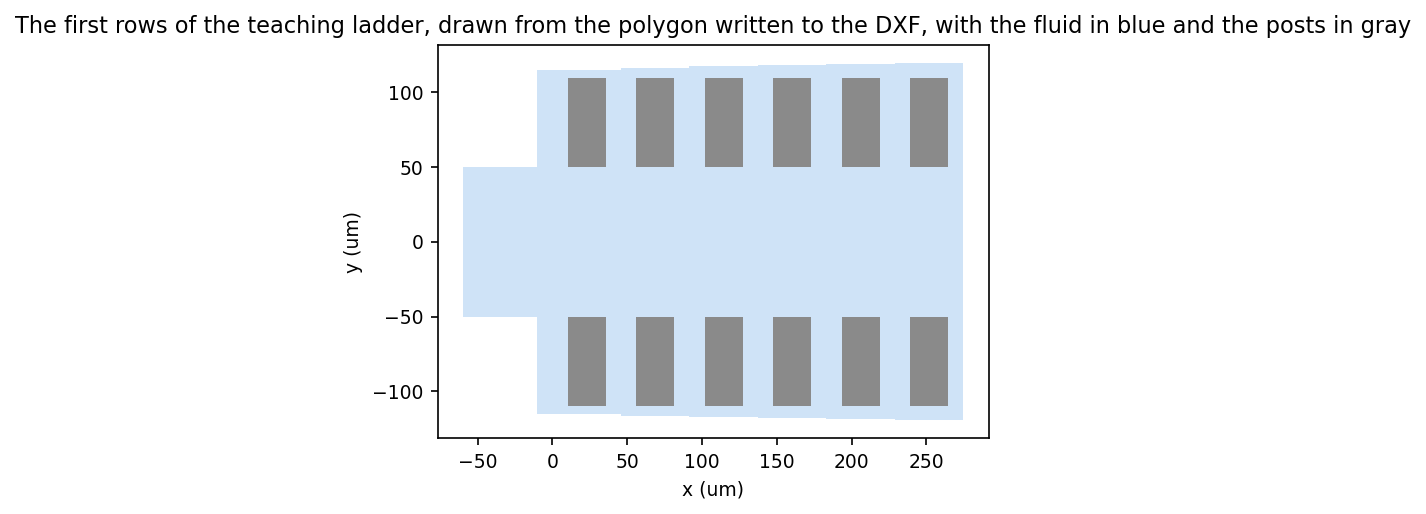

In [15]:
small = T.design(D_um=6.0, F=0.3, depth_um=80, gap_um=20.5, post_um=25.3, wall_um=59.5, centre_um=100)
(OUT / 'teaching').mkdir(exist_ok=True)
path_s = OUT / 'teaching' / 'ladder.dxf'
T.write_photomask(T.draw(small), str(path_s))
a_s = T.audit_photomask(str(path_s), depth_um=80, D_um=6.0)
print('the photomask has %d gaps and %d posts per side; read back, the wall is %.2f um, the gaps %.3f to %.3f um, '
      'and the center %.3f to %.3f um' % (a_s['gaps_per_side'], a_s['posts_per_side'], a_s['wall_um'], *a_s['gap_um'], *a_s['centre_um']))
print('realized cutoff at every gap %.6f to %.6f um (D = 6 um; largest relative deviation %.1e)'
      % (*a_s['D_um'], a_s['D_rel_dev_max']))
print('filtrate fraction on the drawn mask %.6f (the design gives %.6f)' % (a_s['F'], small.F))
fig, ax = plt.subplots(figsize=(10, 3.4))
fl_ = T.draw(small)
from shapely.geometry import box as _box
win_ = fl_.intersection(_box(-60, -260, 6 * small.pitch, 260))
for g_ in [p_ for p_ in getattr(win_, 'geoms', [win_]) if p_.geom_type == 'Polygon']:   # the window's edge can
    xs_, ys_ = g_.exterior.xy                                                              # leave line pieces
    ax.fill(xs_, ys_, color='#cfe3f7', lw=0)
    for r_ in g_.interiors:
        xi_, yi_ = r_.xy
        ax.fill(xi_, yi_, color='#8a8a8a', lw=0)
ax.set_aspect('equal'); ax.set_xlabel('x (um)'); ax.set_ylabel('y (um)')
ax.set_title('The first rows of the teaching ladder, drawn from the polygon written to the DXF, with the fluid in blue and the posts in gray')
show(fig, 'fig_5_teaching_ladder')

### 5.1 A seeded fault

The cell below widens one gap of the drawing by 0.6 µm (2.9% of its 20.5 µm), writes the photomask again, and audits
it blind. The widened gap skims more than its share, so its cutoff rises, and the audit finds it at that row without
being told where to look. The physics auditor of section 7 does the same on every photomask that the generator writes,
with the parts of the full device, and its check P5 fails a gap whose lamina exceeds $\delta^*$ by more than 2%.

largest deviation of the realized cutoff +3.05% at gap 201 (side A)


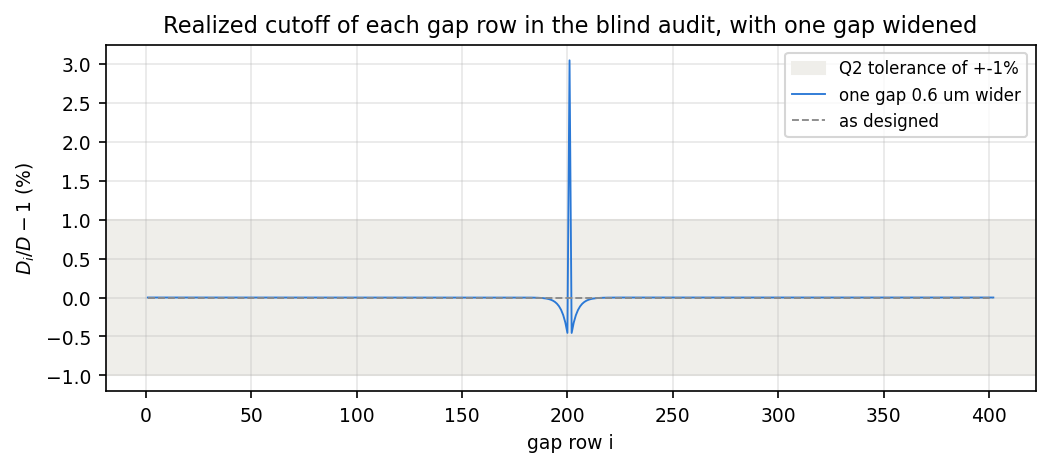

In [16]:
k_ = 200                                                   # gap 201 (index 200), side A
x_ = k_ * small.pitch
bad_ = T.draw(small).union(_box(x_ + small.G / 2 - 0.01, small.w_c / 2 + 0.5, x_ + small.G / 2 + 0.6,
                                small.w_c / 2 + small.l_g - 0.5))
path_b = OUT / 'teaching' / 'ladder_one_gap_wider.dxf'
T.write_photomask(bad_, str(path_b))
a_b = T.audit_photomask(str(path_b), depth_um=80, D_um=6.0)
dev_ = a_b['D_rows'][:, 0] / 6.0 - 1
print('largest deviation of the realized cutoff %+.2f%% at gap %d (side A)' % (100 * np.nanmax(dev_), int(np.nanargmax(dev_)) + 1))
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.axhspan(-1, 1, color='#efeeea', label='Q2 tolerance of +-1%')
ax.plot(np.arange(1, len(dev_) + 1), 100 * dev_, color='#2a78d6', lw=0.9, label='one gap 0.6 um wider')
ax.plot(np.arange(1, len(dev_) + 1), 100 * (a_s['D_rows'][:, 0] / 6.0 - 1), color='#8a8a8a', lw=0.9, ls='--', label='as designed')
ax.set_xlabel('gap row i'); ax.set_ylabel('$D_i / D - 1$ (%)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title('Realized cutoff of each gap row in the blind audit, with one gap widened')
show(fig, 'fig_5_seeded_fault')

## 6. One call: from $(D, F)$ to a photomask

The call `opencif.generate(D, F)` builds the whole device. It writes the specification it used (with every default
recorded), plans the rows, draws the photomask, measures the drawn polygons (every side segment, head unit, turn, and
outlet lead), solves the 1-D flow network on the drawn geometry, checks the result, and audits the photomask file
(section 7). Without other arguments, it uses the `generic19` process (100 µm deep, with 19 µm gaps and a 19 µm floor),
one straight leg, a constant center width $w_c = D/0.05$, a packed meander head, a plain inlet, separate outlets, and
strict mode (`docs/OPTIONS.md` lists every part and default). The packed meander head consists of long folded
channels, 1.45 times the gap wide, that carry the tiny side flows of the first rows, so that the start is sealed and
gap 1 skims exactly the design fraction $f^*$. The cell below builds a device with $D$ = 4 µm and $F$ = 0.5, which
takes about 2 to 10 minutes, toward the longer end while the builds of section 10 run beside it.

In [17]:
t0 = time.time()
first = opencif.generate(4.0, 0.5, out=OUT / 'first')
print('%.0f s' % (time.time() - t0))
d = first.record['design']
print('verdict  :', first.verdict)
print('exit code:', first.exit_code, '(0 = PASS)')
print('N = %d gap rows (%d of them in the meander head), F planned %.5f, F on the drawn mask %.5f'
      % (d['N'], d['NM'], d['F'], first.record['validation']['network']['F_as_drawn']))
print('photomask:', os.path.relpath(first.dxf, HERE), '| sha256', sha256(first.dxf)[:16])
print('physics audit of the photomask file:', first.physics_audit)
print('spec written to', os.path.relpath(first.spec_path, HERE), '(to rebuild it, run python -m opencif build <that file> --out DIR)')

261 s
verdict  : PASS [1-D model: junction band: 3 row(s) beyond +-1% (up to 16.4% of D; rows 71-73; 0.35% of F)]
exit code: 0 (0 = PASS)
N = 1124 gap rows (72 of them in the meander head), F planned 0.50030, F on the drawn mask 0.50030
photomask: tutorial_out/first/cif_D4_F0p5.dxf | sha256 02a2d5490b27895d
physics audit of the photomask file: PASS
spec written to tutorial_out/first/cif_D4_F0p5_spec.yaml (to rebuild it, run python -m opencif build <that file> --out DIR)


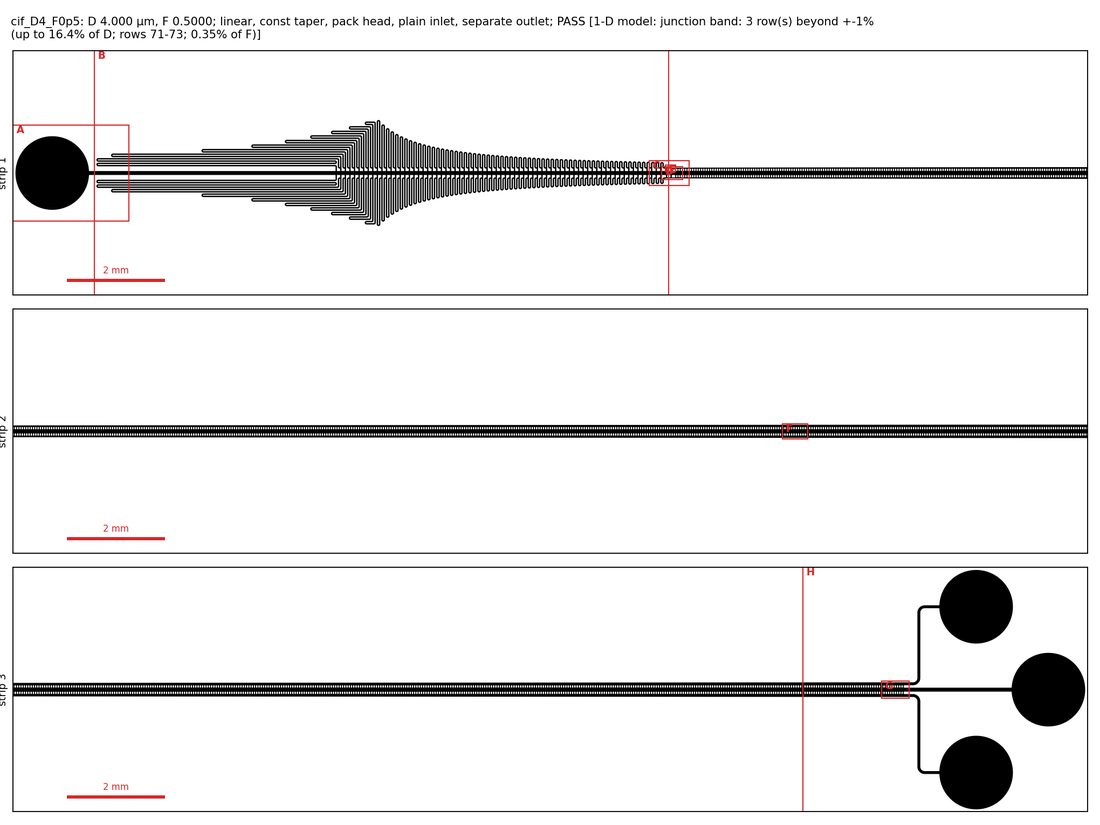

(preview; full resolution: tutorial_out/first/cif_D4_F0p5_layout.png)


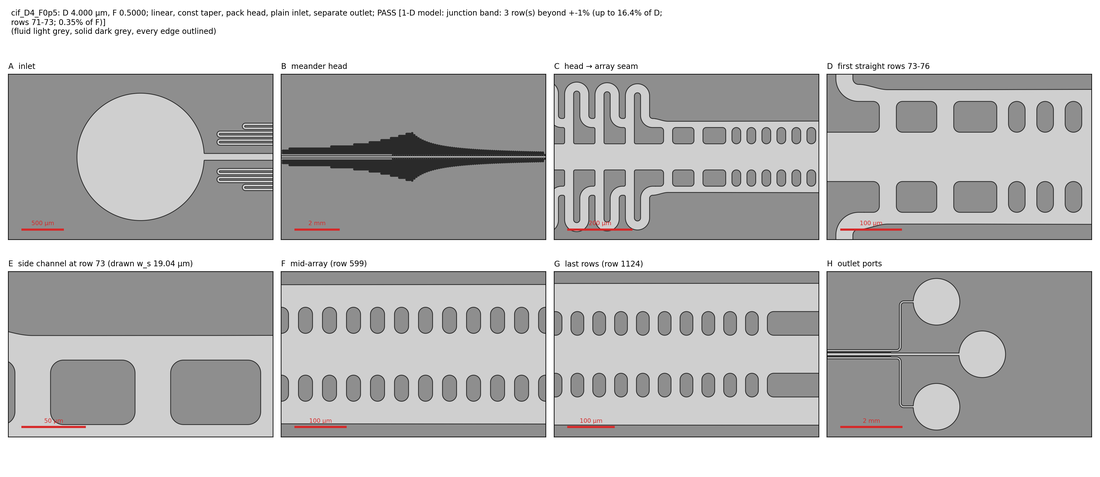

(preview; full resolution: tutorial_out/first/cif_D4_F0p5_zooms.png)


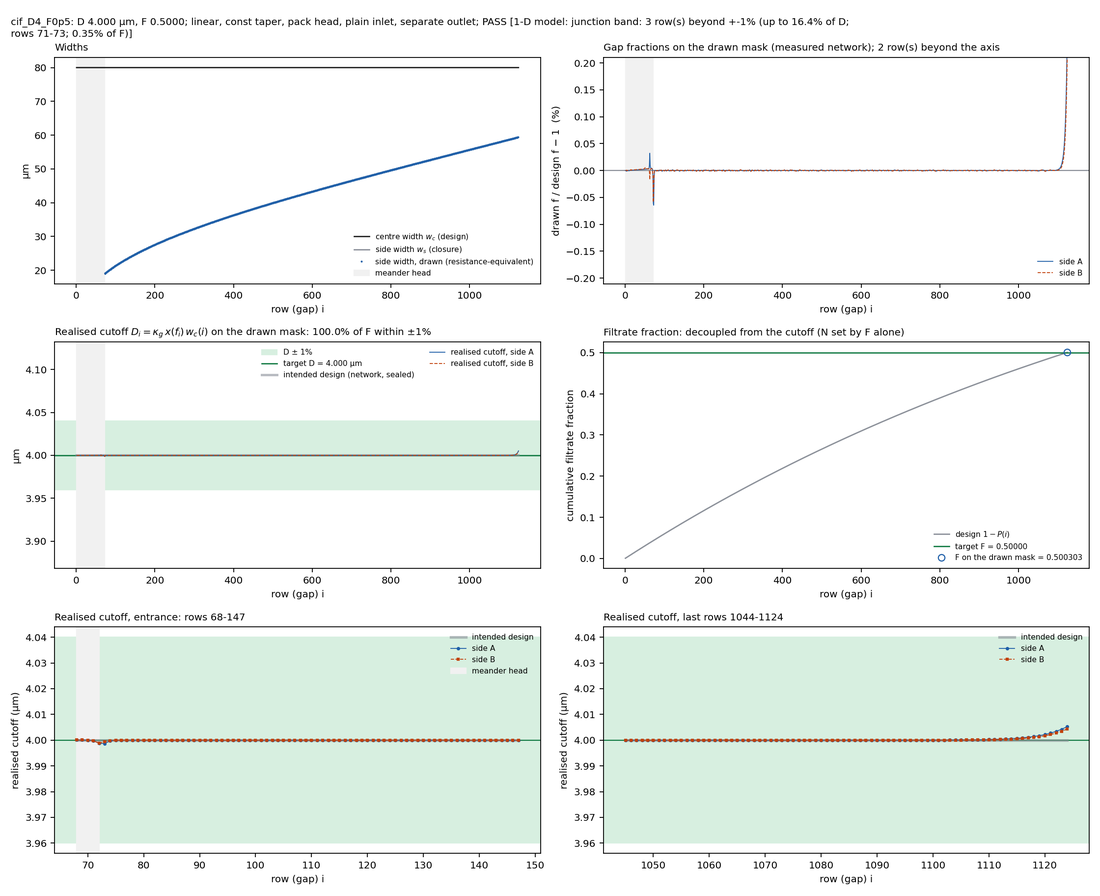

(preview; full resolution: tutorial_out/first/cif_D4_F0p5_physics.png)


In [18]:
for fig_path in first.figures:          # the build's own proof figures (the layout, the zoom windows, and the physics panel)
    preview(fig_path)

### 6.1 What the record checks

The record (`<name>.json`) holds every check, and `assessment.status` summarizes them. Two checks carry the physics on
the drawn mask. Q1 requires that the network solved on the drawn geometry deliver the designed fraction at every gap.
Q2 requires that the cutoff each gap realizes on the drawn mask, $D_i$, be within the tolerance (±1%) of $D$, and that
the delivered $F$ be within its tolerance of the target. In reproduce mode (section 10), a row is exempt from Q2 only
when a declared departure (a seed gap, a head drawn as depicted, a floor start, the papers' transition, or the loop
pull-in) is shown to move it (`docs/REFERENCE.md`, "What every build checks").

The $F$ reported here is the filtrate fraction of the 1-D network on the drawn mask. The 3-D flow at the outlet
bifurcation is not modeled. On Dinh's V1, the measured $F$ was about 10% below the 1-D value (the glossary's
$\eta = 0.903$), and Appendix B attributes the difference to the outlet's geometry (P-C4.2), so a fabricated device's
$F$ may fall short of the 1-D value by a similar amount. Every record reports $\eta F$ beside $F$, as the design code
does, and never applies it (`validation.design_code_reports.B6_F_real`; `docs/LIMITATIONS.md`, item 5; section 11).

The cell below plots $D_i/D - 1$ for both side channels from the arrays that the build saved in `<name>.pkl`. Only a
pickle file written by one's own run should be loaded, because unpickling can execute code.

The bracket that follows the verdict is a different quantity from Q2. It is the 1-D model band (`docs/REFERENCE.md`,
"What every build checks"), which comes from re-solving the same drawn network with the junction terms (the bends and
the T-junctions of the head) and the end of the outlet stretch at the two ends of their uncertainty. The band is
reported and is never a pass condition. Here it moves the rows at the seam between the meander head and the straight
section, which are the rows most sensitive to the head's resistance. The rows "losing their cutoff" in that bracket are
rows inside the tolerance on the drawn mask that, in one of those scenarios, would have reverse flow or would skim half
the flow or more ($f \ge 1/2$), so that no cutoff is defined there.

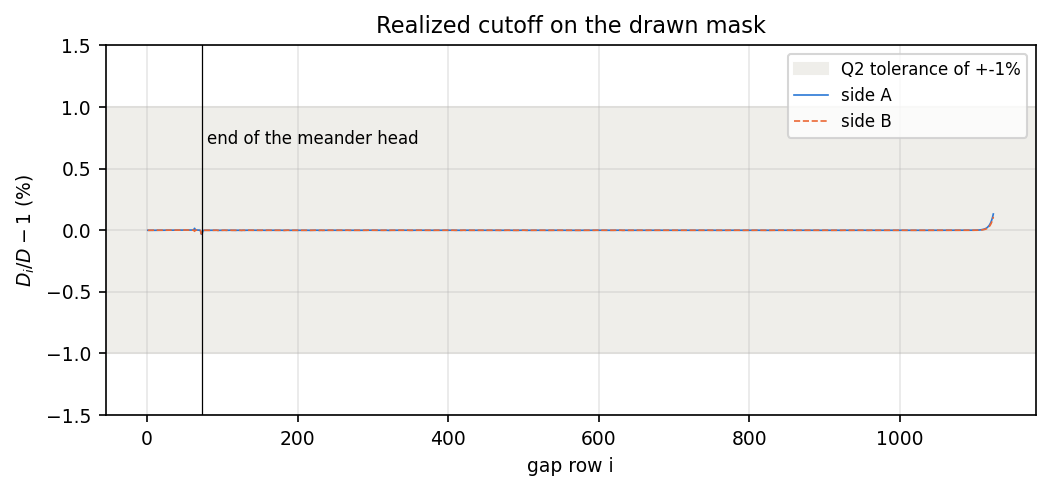

realized cutoff range 3.9987 to 4.0053 um (D = 4.0 um); share of F through rows within 1% of D: 1.000
status:
  hard_checks                    PASS
  validity_envelope              INSIDE
  chip_area                      NOT GIVEN
  aspect_ratio_of_CIF_channels   WITHIN THE LIMIT
  length_budget_G9               NOT GIVEN (no chip)
  drawn_mask_assessment          RUN: opencif's own checks on the drawn polygons (DRC at the floor, topology, continuity, ports, clearances, co
  physics_audit                  PASS: the photomask file read back passes the physics auditor (CIF_v2's P1-P10 ported; P0: the file is the dra
  fabricated_or_measured         NO: Q1 and Q2 are statements of the 1-D network on the drawn mask
  reproduction                   NOT CLAIMED: not a reproduction (gates.mode is not reproduce)
  source_trace                   NOT NAMED: the spec names no trace of this device against its source figures


In [19]:
import pickle
arr = pickle.load(open(Path(first.out) / (first.record['design']['name'] + '.pkl'), 'rb'))['arrays']
rc = first.record['validation']['realised_cutoff']
dA, dB = np.asarray(arr['dA'], float), np.asarray(arr['dB'], float)
rows_ = np.arange(1, len(dA) + 1)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axhspan(-1, 1, color='#efeeea', label='Q2 tolerance of +-1%')
ax.plot(rows_, 100 * (dA / rc['D_target_um'] - 1), color='#2a78d6', lw=0.8, label='side A')
ax.plot(rows_, 100 * (dB / rc['D_target_um'] - 1), color='#eb6834', lw=0.8, ls='--', label='side B')
ax.axvline(first.record['design']['NM'] + 0.5, color='k', lw=0.6)
ax.text(first.record['design']['NM'] + 8, 0.7, 'end of the meander head', fontsize=8)
ax.set_xlabel('gap row i'); ax.set_ylabel('$D_i / D - 1$ (%)'); ax.set_ylim(-1.5, 1.5); ax.legend(fontsize=8)
ax.set_title('Realized cutoff on the drawn mask'); ax.grid(alpha=0.3)
show(fig, 'fig_6_realized_cutoff')
print('realized cutoff range %.4f to %.4f um (D = %.1f um); share of F through rows within 1%% of D: %.3f'
      % (rc['D_realised_min_um'], rc['D_realised_max_um'], rc['D_target_um'], rc['share_of_F_within_1%']))
print('status:')
for k, v in first.record['assessment']['status'].items():
    print('  %-30s %s' % (k, v[:110]))

### 6.2 The photomask file and the exit codes

The DXF has two layers, `CHANNELS` (the fluid region, which is one polygon) and `ISLANDS` (the posts and walls inside
it). The cells below read the file with `ezdxf` and draw a window of the straight section from it.

The exit codes 0 and 2 to 6 are defined in `docs/ARCHITECTURE.md`, section 8, and exit 1 in `docs/REFERENCE.md` ("What
every build checks"). An exit code of 0 means PASS (or REPRODUCED), and 2 means FAIL, because a hard check failed, the
physics audit's among them (the mask is kept as `<name>_FAILED.dxf`). An exit code of 3 means outside the validity
envelope in evaluate or reproduce mode, 4 means INCOMPLETE, 5 means REFUSED (no photomask is written, and the record
`<name>.json` gives the reasons and the cutoff band), and 6 means an invalid specification. An exit code of 1 means that
the generator could not draw the request because of an unanticipated exception, in which case no record is written.

In [20]:
import ezdxf
from matplotlib.patches import Polygon as MplPolygon
doc = ezdxf.readfile(first.dxf)
msp = doc.modelspace()
layers = {}
for e in msp:
    layers.setdefault(e.dxf.layer, []).append(e)
print({k: len(v) for k, v in layers.items()}, 'entities per layer')
from shapely.geometry import Polygon as ShPolygon
outline = [e for e in layers['CHANNELS'] if e.dxftype() == 'LWPOLYLINE'][0]
fluid = ShPolygon([(p[0], p[1]) for p in outline.get_points('xy')])
x0_, y0_, x1_, y1_ = fluid.bounds
print('the fluid outline has %d vertices, and the whole mask measures %.1f × %.1f mm' % (len(fluid.exterior.coords), (x1_ - x0_) / 1000, (y1_ - y0_) / 1000))

{'CHANNELS': 1, 'ISLANDS': 2246} entities per layer


the fluid outline has 106168 vertices, and the whole mask measures 65.4 × 4.9 mm


The polygons are in micrometers. Rather than guessing where the rows are on the chip, the cell below uses the drawn
mask's own coordinates. It takes the posts, which are the ISLANDS smaller than a wall, and zooms in on the one in the
middle of the device.

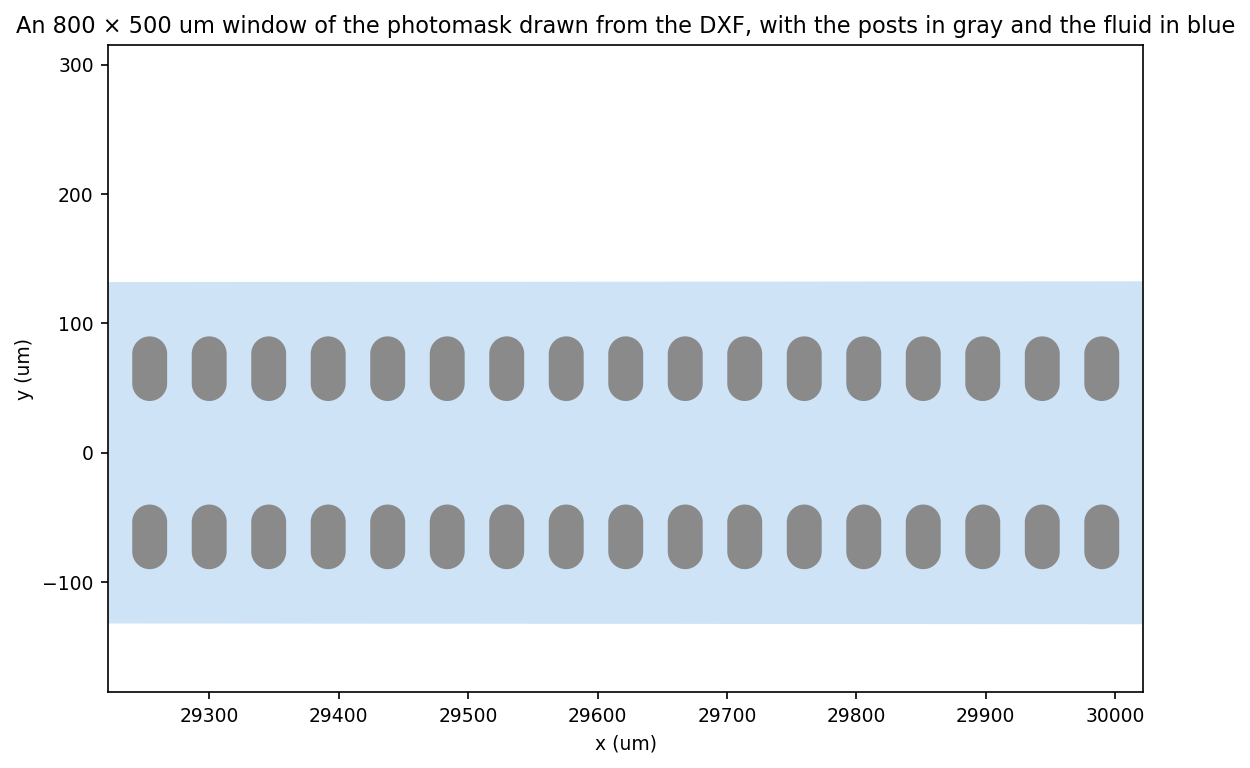

In [21]:
isl = [ShPolygon([(p[0], p[1]) for p in e.get_points('xy')]) for e in layers.get('ISLANDS', [])
       if e.dxftype() == 'LWPOLYLINE' and len(list(e.get_points('xy'))) > 2]
posts_ = sorted([p for p in isl if p.area < 20000], key=lambda p: p.centroid.x)    # the posts; the walls are larger
cx = np.median([p.centroid.x for p in posts_])
mid = min(posts_, key=lambda p: abs(p.centroid.x - cx))
win = (mid.centroid.x - 400, mid.centroid.x + 400, mid.centroid.y - 250, mid.centroid.y + 250)
fig, ax = plt.subplots(figsize=(9, 5.6))
for lay, col in (('CHANNELS', '#cfe3f7'), ('ISLANDS', '#8a8a8a')):
    for e in layers.get(lay, []):
        if e.dxftype() != 'LWPOLYLINE':
            continue
        pts = np.array([(p[0], p[1]) for p in e.get_points('xy')])
        if len(pts) > 2 and pts[:, 0].max() > win[0] and pts[:, 0].min() < win[1] and pts[:, 1].max() > win[2] and pts[:, 1].min() < win[3]:
            ax.add_patch(MplPolygon(pts, closed=True, color=col, lw=0))
ax.set_xlim(win[0], win[1]); ax.set_ylim(win[2], win[3]); ax.set_aspect('equal')
ax.set_xlabel('x (um)'); ax.set_ylabel('y (um)')
ax.set_title('An 800 × 500 um window of the photomask drawn from the DXF, with the posts in gray and the fluid in blue')
show(fig, 'fig_6_photomask_window')

## 7. The physics audit: the photomask read back from its file

The checks of section 6 run on the polygon that the generator drew. The physics audit then reads the photomask back from
its DXF file and checks the physics on what the file contains. It is the design code's own physics auditor (the
`ladder_physics.audit` embedded in `CIF_v2.py`, with checks P1–P10), ported to opencif (`opencif/checks/auditor.py`) and
given its own ruler for the straight rows (`opencif/checks/ruler.py`), and `docs/PHYSICS_AUDIT.md` gives each check's
source and what the port changes. Appendix B says that the targets-to-photomask tool and the machine-enforced validity
envelope (the prospectus's C7 and C8, not Appendix B's claims) are "warranted by their acceptance suite and the physics
auditor" and that "the physics auditor separately checks the drawn device's inlet against its own, stricter channel
limit" (App. B, Scope). Each check has one of three roles. A failed hard check fails the build (exit 2), a failed
envelope check places the drawn device outside the validity envelope (exit 3), and a report is recorded and is never a
pass condition.

| check | what it requires | role |
|---|---|---|
| P0 | the file read back is the drawn polygon, vertex for vertex | hard |
| R0 | the auditor's own ruler measures every ordinary straight row again from the file, and the generator's measurement agrees with it within $10^{-3}$ | hard |
| P1 | the kernels reproduce their published anchors | hard |
| P2 | mass is conserved, in the plan and at every node of the drawn network | hard |
| P3 | the drawn side channels realize the closure | hard |
| P4 | in the bulk of the device, every gap skims the intended network's fraction within 0.5%, which is the kernel's fraction $g(\delta^*/w_c(i))$ in a design without declared departures | hard |
| P5 | no gap's lamina exceeds $\delta^*$ by more than 2%, which is the cutoff guarantee | hard |
| P6, P6b | the filtrate fraction is on target and agrees, within $\max(8\times10^{-3}, 4\bar f)$, with App. A's closed form at the outlet | hard |
| P7 | how much the outlet's matching matters | report |
| P8 | the auditor's own, stricter inlet limit, Re $\le$ 1, whereas the design envelope is Re $\le$ 10 | report |
| M14 | the design code's Reynolds and Stokes gates, on the drawn mask | envelope |
| P9, P9-AR | the fabrication floors and the aspect ratio | hard (P9-AR in strict mode, a report otherwise) |
| R6b | every post of the straight rows, read back from the file, has the process's post dimensions within 0.5 µm | hard |
| P10 | no corner is sharper than the process allows | hard |

The cell below prints the first device's audit from its record.

In [22]:
pa = first.record['validation']['physics_audit']
print('physics audit of %s: %s (%.1f s)' % (pa['photomask'].get('file_final', pa['photomask']['file']), pa['status'], pa['seconds']))
for c in pa['checks']:
    v = c['value']
    short = {k: v[k] for k in list(v)[:3]} if isinstance(v, dict) else v
    print('%-7s %-9s %-8s %s' % (c['id'], 'ok' if c['ok'] else ('reported' if c['role'] == 'report' else 'FAIL'),
                                 c['role'], json.dumps(short, default=float)[:110]))
print('P8, the auditor\'s own limit:', next(c for c in pa['checks'] if c['id'] == 'P8')['value']['result'])

physics audit of cif_D4_F0p5.dxf: PASS (16.1 s)
P0      ok        hard     {"identical_to_drawn_polygon": true, "fluid_outlines": 1, "islands": 2246}
R0      ok        hard     {"segments": 1047, "gaps": 2096, "gap_share": 0.932}
P1      ok        hard     {"duct_bracket_1": 0.42173104564946295, "square_duct_R": 28.454153716665743, "g_0p3": 0.21600000000000003}
P2      ok        hard     {"march_identity": 4.33e-15, "kcl_residual_max": 4.89e-13, "product_form": 5.09e-12}
P3      ok        hard     {"exact_closure_max_rel_dev": 2.29e-05, "at": [71, "A"], "pe_closure_max_rel_dev": 0.00716}
P4      ok        hard     {"reference": "the intended network", "bulk_max": 0.000645, "bulk_max_row": 73}
P5      ok        hard     {"max_delta_over_delta_star": 1.0013, "min_delta_over_delta_star": 0.99968, "rows_without_cutoff": 0}
P6      ok        hard     {"F_drawn": 0.500303, "F_march": 0.5002993, "F_target": 0.5}
P6b     ok        hard     {"F_identity": 0.5004284, "F_drawn": 0.500303, "differ

The check P8 is the one that the sentence of Appendix B describes, because it compares the drawn inlet with the
auditor's own, stricter limit (Re $\le$ 1). At this device's flow of 30 µL/min, the inlet runs at Re 5.6, which is
inside the channel gate of the design envelope (Re $\le$ 10, check M14) and above the auditor's own limit, which the
inlet would meet at 5 µL/min, the auditor's default flow. The audit records both, and only the envelope's gate decides
the verdict (`docs/PHYSICS_AUDIT.md`; `docs/LIMITATIONS.md`, item 6).

### 7.1 The audit from scratch

The command `python -m opencif audit <folder>` (or `auditor.audit_run`) repeats the audit of a finished build,
starting from the record's input alone. It plans and draws the design again, reads the DXF, requires the file to equal
that drawing, measures the polygon read from the file with both rulers, runs the DRC on the file, and loads no saved
Python object. It must give the same verdict for every check. A check's recorded value can differ a little, because
the design is planned, drawn and measured again and the record keeps each residual to a few significant digits,
together with the row where it peaks. The cell below compares both in about a minute.

In [23]:
from opencif.checks import auditor as AU
t0 = time.time()
again = AU.audit_run(first.out, say=lambda m: None)
def _nums(v):
    '''the numbers in a check's value, in a fixed order'''
    if isinstance(v, bool) or v is None or isinstance(v, str):
        return []
    if isinstance(v, (int, float)):
        return [float(v)]
    if isinstance(v, dict):
        return [x for k in sorted(v) for x in _nums(v[k])]
    return [x for e in v for x in _nums(e)]
same_ = len(pa['checks']) == len(again['checks']) and all(a_['id'] == b_['id'] and a_['ok'] == b_['ok']
                                                          for a_, b_ in zip(pa['checks'], again['checks']))
off_ = [a_['id'] for a_, b_ in zip(pa['checks'], again['checks']) if _nums(a_['value']) != _nums(b_['value'])]
print('standalone audit %s in %.0f s; every check\'s verdict equal to that of the build\'s own audit: %s' % (
    again['status'], time.time() - t0, same_))
print('checks whose recorded value differs (a residual\'s last digits or the row where it peaks): %s'
      % (', '.join(off_) if off_ else 'none'))

standalone audit PASS in 181 s; every check's verdict equal to that of the build's own audit: True
checks whose recorded value differs (a residual's last digits or the row where it peaks): R0, P2, P4, P5


The suite `tests/test_auditor.py` runs the port beside the design code's own auditor on the design code's three
demonstration devices, which give the same numbers and the same verdicts. It then seeds fourteen faults into a drawn
device, one at a time, among them an intended network 1% away from the drawn one, a vertex of the file moved by 1 nm, a
kernel shifted by $10^{-9}$, a gap widened by 0.6 µm, a side segment narrowed, a post thickened or moved, another
device's photomask under the build's name, the flow tripled, a lost feature, a sharp corner, a raised target $F$, and a
tighter aspect-ratio limit. Each fault is caught by the check meant to catch it (`docs/PHYSICS_AUDIT.md`, "Validation of
the port").

## 8. The validity envelope and the designs the generator refuses

The cutoff law and the 1-D model hold only inside an envelope (App. B, thesis and scope; the design code's gates;
`docs/REFERENCE.md`, "What every build checks"). In strict mode, which is the default, a design outside the envelope is
refused before anything is drawn (exit 5), and the reason is given. The $\kappa$ plateau gate requires
$\tilde d = D/w_c \ge 0.035$ at the widest center width, together with the foot (App. B, C3c). The channel Reynolds
number must satisfy $\mathrm{Re} \le 10$, and the Stokes gates require $\mathrm{Re}_{\mathrm{gap}}\le10^{-2}$ and
$\mathrm{Re}_\delta\le10^{-2}$, which are the Reynolds numbers of the flow through a gap and of the skimmed lamina
(App. B's thesis states that "the Stokes regime is gated in code"; the design code's M14). Gap dominance requires
$R_{\mathrm{gap}}f/R_c < 0.05$ (the design code's M13; spec v5, section 19), the thin lamina requires
$\delta/h \le 0.10$ (E11), and a taper must be quasi-developed (M16). Finally, the process floor
$w_{\min}=\max(F_{\min}, h/\mathrm{AR}_{\max})$ applies to the gap, the head's channel, every center width, and every
straight side channel (G7). On the drawn mask, the aspect ratio of the narrowest channel is then a pass condition
(exit 2 in strict mode), and the physics audit evaluates the Reynolds and Stokes gates again on the drawn mask (M14,
section 7).

In evaluate mode, the same design is drawn and reported (exit 3). Reproduce mode is evaluate mode plus the papers'
deliberate departures (a seed gap, a head drawn as depicted, a floor start, the papers' transition, and the loop
pull-in), each declared row by row (section 10). The cells below plan three refused designs, which takes seconds each.

In [24]:
cases = [('off the plateau (D = 2 um on a 100 um center channel)', dict(cutoff=2.0, F=0.5, taper=('constant', 100))),
         ('too fast (200 uL/min)', dict(cutoff=4.0, F=0.5, flow_uL_min=200)),
         ('gap dominance and the Stokes gates (D = 6 um on an 80 um channel, 100 um deep)', dict(cutoff=6.0, F=0.5, taper=('constant', 80)))]
for k, (title, kw) in enumerate(cases, 1):
    kw = dict(kw); Dv, Fv = kw.pop('cutoff'), kw.pop('F')
    parts = dict(DC); parts.update(kw)
    r = opencif.generate(Dv, Fv, out=OUT / 'plans', check_only='plan', name='refused_%d' % k, **parts)
    print('%s\n   exit %d: %s\n' % (title, r.exit_code, r.verdict))

off the plateau (D = 2 um on a 100 um center channel)
   exit 5: WOULD BE REFUSED: kappa plateau (u_min 0.0200 < 0.035 at the widest centre width 100.0 um, before the head's sealing search)



too fast (200 uL/min)
   exit 5: WOULD BE REFUSED: Reynolds 37.04 > 10; Stokes gates (Re_gap 1.73e-02 at row 1, Re_delta 3.12e-02 at row 1; both must be <= 0.01)



gap dominance and the Stokes gates (D = 6 um on an 80 um channel, 100 um deep)
   exit 5: WOULD BE REFUSED: gap dominance M13 0.0538 >= 0.05; Stokes gates (Re_gap 5.81e-03 at row 1, Re_delta 1.05e-02 at row 1; both must be <= 0.01)



In [25]:
import yaml
# The same straight Gifford-style example at 30 uL/min. Strict mode refuses it, because the lamina's Reynolds number at
# gap 1 is just above 1e-2, whereas evaluate mode plans it and reports it (exit 3).
for mode in ('strict', 'evaluate'):
    d_ = yaml.safe_load(open(TREE / 'examples' / 'gifford_physics_linear.yaml'))
    d_['name'] = 'gifford_linear_30_' + mode
    r = opencif.generate(d_['targets']['cutoff_um'], d_['targets']['filtrate_fraction'], process=d_['process'],
                         chip=d_['chip'], taper=d_['centre_channel'], layout=d_['layout'], meander=None,
                         inlet=d_['inlet'], outlet=d_['outlet'], flow_uL_min=30, mode=mode, name=d_['name'],
                         out=OUT / 'plans', check_only='plan')
    print('%-8s exit %d: %s' % (mode, r.exit_code, r.verdict))

strict   exit 5: WOULD BE REFUSED: Stokes gates (Re_gap 4.41e-03 at row 1, Re_delta 1.05e-02 at row 1; both must be <= 0.01)


evaluate exit 3: planned only (no outline: check_only='plan'): outside the envelope: Stokes gates (Re_gap 4.41e-03 at row 1, Re_delta 1.05e-02 at row 1; both must be <= 0.01)


## 9. Composing new devices from parts

A device is composed of parts, each of which is a section of the specification. For each part, `docs/OPTIONS.md` gives
the styles, the origin, an example, and the record field that verifies the part on the drawn mask.

| part | styles | origin |
|---|---|---|
| `layout` | `linear`, `serpentine` (legs side by side), `paperclip` (nested legs) | Gifford 2014 Fig. 1 (linear); Gifford 2014 Fig. 4 and Xia 2016 Fig. 3a (paperclip); this project (serpentine) |
| `centre_channel.taper` | `constant`, `constant_shear` (narrows as the flow drops, holding the wall shear) | Gifford 2014; Xia 2016 |
| `meander` (the head) | `pack`, `arms`, `hairpins`, `narrow`, or none | this project; Dinh 2024; Xia 2016; this project |
| `inlet` | `plain`, `filter`, `dinh_filter` | this project (filter); Dinh 2024 Fig. 2A (dinh_filter) |
| `outlet` | `separate`, `teardrop`, `ring` | Gifford 2014 Fig. 4; Dinh 2024 Fig. 2A; after Xia 2016 Fig. 3a |
| `start` | `sealed`, `floor` (no head; the first side channel is at the process floor) | Gifford 2014 Fig. 2 (sealed) and p. 4498 (floor); App. A Result 10 |
| `array` | $n$ copies of a passing element, one inlet | this project (`opencif.compose`) |

Every part is resistance-exact and is checked gap by gap on the drawn mask. This section builds three new devices. The
first is a serpentine platelet-scale device on a chip the size of a microscope slide, the second is a nested paperclip
with a ring outlet (one of the release's own test designs, which we rebuild here and compare with the release's
photomask byte for byte), and the third is an array of three copies.

1087 s | exit 0 | PASS [1-D model: junction band: 18 row(s) beyond +-1%, 2 losing their cutoff (up to 61.7% of D; rows 163-166, 1968-1981; 0.78% of F)]
N = 1981 rows (164 in the head), 3 legs, F on the drawn mask 0.60020; over the chip area: False


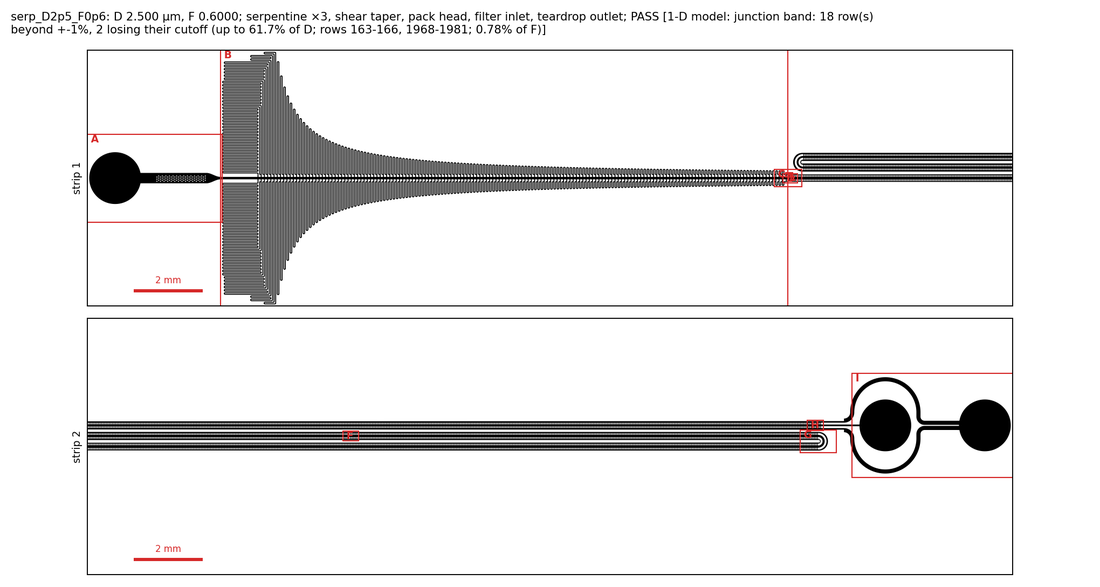

(preview; full resolution: tutorial_out/serpentine/serp_D2p5_F0p6_layout.png)


In [26]:
t0 = time.time()
serp = opencif.generate(2.5, 0.6, process='dinh2024', chip=(25, 75), layout='serpentine',
                        taper=('constant_shear', 70, 50), meander='pack', inlet='filter', outlet='teardrop',
                        out=OUT / 'serpentine', name='serp_D2p5_F0p6')
print('%.0f s | exit %d | %s' % (time.time() - t0, serp.exit_code, serp.verdict))
dd = serp.record['design']
print('N = %d rows (%d in the head), %d legs, F on the drawn mask %.5f; over the chip area: %s'
      % (dd['N'], dd['NM'], dd.get('n_legs', 1), serp.record['validation']['network']['F_as_drawn'], serp.over_chip_area))
preview(serp.figures[0])

# Variant matrix (pairwise covering of layout x taper x meander style x inlet x outlet), one base design:
# D 4.0 um, F 0.5, 100 um deep, 19 um gaps and floor, w_c 80 um (u_min 0.05: inside the kappa plateau).
name: m11_paperclip_const_pack_filter_ring
targets: {cutoff_um: 4.0, filtrate_fraction: 0.5}
process: {depth_um: 100, gap_um: 19, post_length_um: 27, post_width_um: 50, min_feature_um: 19}
chip: {width_mm: 12, length_mm: 30, margin_um: 1000}
centre_channel: {taper: constant, width_in_um: 80}
layout: {style: paperclip, legs: auto}
meander: {enabled: true, style: pack, channel_um: 28, wall_um: 27, seal: require}
inlet: {style: filter, port_radius_um: 750}
outlet: {style: ring, port_radius_um: 750, centre_port_radius_um: 750}
gates: {mode: strict}



390 s | exit 0 | PASS [1-D model: junction band: 22 row(s) beyond +-1%, 2 losing their cutoff (up to 57.9% of D; rows 71-73, 1106-1124; 1.5% of F)]
photomask sha256 b1c8365b04cb28598e0cf3fa635cd662ce7f40781f19b1d2d5f5c2d42f8935f3
released sha256  b1c8365b04cb28598e0cf3fa635cd662ce7f40781f19b1d2d5f5c2d42f8935f3
byte-identical to the release's own build: True
physics audit: PASS


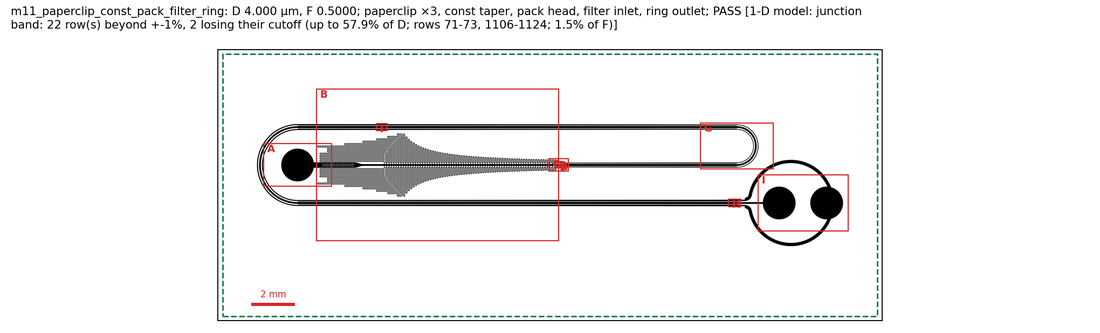

(preview; full resolution: tutorial_out/m11_paperclip_const_pack_filter_ring/m11_paperclip_const_pack_filter_ring_layout.png)


In [27]:
name = 'm11_paperclip_const_pack_filter_ring'
spec_path = TREE / 'examples' / 'matrix' / (name + '.yaml')
print(open(spec_path).read())
t0 = time.time()
rec = PL.run(str(spec_path), str(OUT / name), verbose=False)
dxf = OUT / name / (name + '.dxf')
print('%.0f s | exit %d | %s' % (time.time() - t0, rec['assessment']['exit_code'], rec['assessment']['verdict']))
print('photomask sha256 %s\nreleased sha256  %s\nbyte-identical to the release\'s own build: %s'
      % (sha256(dxf), FROZEN[name]['dxf_sha256'], sha256(dxf) == FROZEN[name]['dxf_sha256']))
print('physics audit:', rec['validation']['physics_audit']['status'])
preview(OUT / name / (name + '_layout.png'))

483 s | element: exit 0 | PASS [1-D model: junction band: 3 row(s) beyond +-1% (up to 9.6% of D; rows 44-46; 0.36% of F)]
array: PASS: 3 copies of the validated element (D 5.0000 um, F 0.50030 on its drawn mask), outlets per element [1-D model: junction band: 3 row(s) beyond +-1% (up to 9.6% of D; rows 44-46; 0.36% of F)]


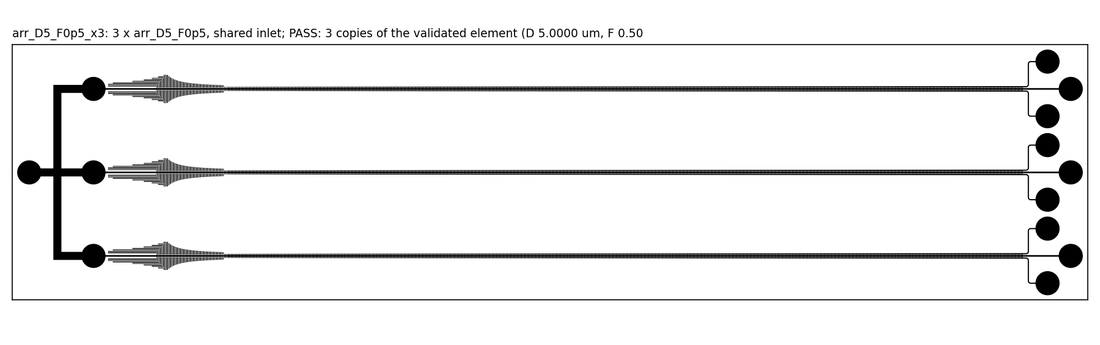

(preview; full resolution: tutorial_out/array/arr_D5_F0p5_x3_layout.png)


In [28]:
# An array of three copies of a passing element (D = 5 um, F = 0.5, straight, with a packed head) that share one inlet.
# Each copy keeps its own outlets, so each realizes the element's D and F regardless of what the inlet manifold does
# (docs/REFERENCE.md, Composition).
t0 = time.time()
arr3 = opencif.generate(5.0, 0.5, array=dict(count=3, inlet='shared'), out=OUT / 'array', name='arr_D5_F0p5')
print('%.0f s | element: exit %d | %s' % (time.time() - t0, arr3.exit_code, arr3.verdict))
a_ = arr3.record.get('array') or {}
print('array:', a_.get('verdict', a_))
for f_ in sorted(glob.glob(str(OUT / 'array' / '*_x3*.png'))):
    preview(f_)

## 10. Reproducing the published devices

The release carries presets for devices of the three papers. Every value in a preset carries one of five source tags
(`docs/PRESET_PROVENANCE.md`). The tag P marks a printed value, M a value measured on a figure, D a value derived
through the frozen model or fitted to a measurement, A an assumed value, and G the generator's choice. The
reproductions are at the design level, meaning that they reproduce the papers' design quantities and align with their
micrographs, whereas no device was fabricated or measured (`docs/REPRODUCTIONS.md`). Every preset runs in reproduce
mode, in which the device is drawn with the paper's deliberate departures, each declared and attributed row by row
(`docs/OPTIONS.md`, `gates.mode`). A preset outside the validity envelope is drawn and reported with exit 3, which
here applies to Gifford's Fig. 6 ($\tilde d_{\min}$ = 0.029) and to Xia's RS-7 ($\tilde d_{\min}$ = 0.021, which also
fails M13, the channel Reynolds number, and the Stokes gates). Dinh's figure-aligned preset (with its cutoff fitted to
3.67 µm) and Gifford's Fig. 4 lie inside the envelope and reproduce with exit 0. At 2.17 µm, the cutoff that Dinh's
printed $f^*$ = 1.04 × 10⁻⁴ at $w_c$ = 75 µm implies through $\kappa_g$ at leading order, the plateau guard would
refuse the device, as it would Xia's RS-7 (App. B, C8, CQ7, where Dinh's widest end
"gives u = d/w_c = 0.029 ... and the plateau guard refuses it").

| preset | paper | what is reproduced |
|---|---|---|
| `dinh2024_v1_figure_aligned` | Dinh 2024, V1 (platelets) | the printed design, with $D$ fitted to the printed length |
| `gifford2014_fig4_aligned` | Gifford 2014, Fig. 4 | the nested four-leg device of the inset (the widths of leg 2 remain open, register GIF4-1) |
| `gifford2014_fig6_aligned` | Gifford 2014, Fig. 6 (platelets) | seven nested legs, with the start fitted on leg 1 |
| `xia2016_rs7_aligned` | Xia 2016, RS-7 (leukocytes) | the constant-shear taper and hairpin head, with $D$ and $F$ fitted to Fig. 3 |

The first cell below prints the header of `presets/gifford2014_fig4_aligned.yaml`, which gives the source of its
values, and the second plans the four presets and prints each plan beside the release's build of the same preset.

In [29]:
head = open(TREE / 'presets' / 'gifford2014_fig4_aligned.yaml').read().split('\nname:')[0]
print(head[:2600], '\n...')

# Gifford 2014, Fig. 4 bead device -- ALIGNED reproduction (RC8; register GIF4-1 / INV-2): the NESTED reading.
# Supported by four lines of evidence that agree (RC8; third-party review 1 of rc7, review8, review 3):
#   1. the caption: "The inset shows an image of the second and fourth legs of the device during operation";
#   2. the schematic: the four legs nested (the layout's default order);
#   3. the inset's two arrows point the same way (consecutive legs of a path-order layout flow opposite ways; Fig. 6
#      draws one arrow per leg, all co-directional); the weakest line: their placement, symmetric about leg 4 (one
#      between the legs, one outside leg 4), also allows both to mark leg 4;
#   4. the neighbour's taper direction (side channels widen along the flow, Gifford Fig. 1 caption): V13, the
#      taper-direction sign test, PASSES on this reading (the neighbour, leg 2, widens the way leg 4 flows) and FAILS on
#      the path-order reading B (provenance/rc7_traces/variants

In [30]:
import yaml
for n in REPRO:
    t0 = time.time()
    dsp = yaml.safe_load(open(TREE / 'presets' / (n + '.yaml')))
    S.clear_caches()
    spec_, opts_, sc_, g_, env_bad_, notes_ = PL.prepare(SP.load(dsp), lambda m: None)
    print('%-28s planned in %4.1f s, N %5d, head rows %3d, F %.5f, D %.4f um; outside the envelope: %s'
          % (n, time.time() - t0, sc_.N, sc_.NM, sc_.F, S.KAPPA_G * spec_.delta_star, '; '.join(env_bad_) or 'no'))
    print('%-28s the release\'s build, exit %d, N %d, F %.5f, physics audit %s' % ('', FROZEN[n]['exit_code'], FROZEN[n]['N'],
                                                                                FROZEN[n]['F_design'], FROZEN[n]['physics_audit']))

dinh2024_v1_figure_aligned   planned in 21.4 s, N  1093, head rows 219, F 0.55927, D 3.6700 um; outside the envelope: no
                             the release's build, exit 0, N 1093, F 0.55927, physics audit PASS


gifford2014_fig4_aligned     planned in 51.7 s, N  3543, head rows   0, F 0.90650, D 5.2032 um; outside the envelope: no
                             the release's build, exit 0, N 3543, F 0.90650, physics audit PASS


gifford2014_fig6_aligned     planned in 90.8 s, N  5783, head rows   0, F 0.72926, D 3.6236 um; outside the envelope: kappa plateau (u_min 0.0290 < 0.035)
                             the release's build, exit 3, N 5783, F 0.72926, physics audit PASS


xia2016_rs7_aligned          planned in 16.5 s, N  8106, head rows  29, F 0.94073, D 6.4159 um; outside the envelope: kappa plateau (u_min 0.0214 < 0.035); gap dominance M13 0.2584 >= 0.05; Reynolds 60.61 > 10; Stokes gates (Re_gap 1.93e-02 at row 3396, Re_delta 3.63e-02 at row 3396; both must be <= 0.01)
                             the release's build, exit 3, N 8106, F 0.94073, physics audit PASS_OUTSIDE_ENVELOPE


### 10.1 The full builds

The full builds were started in section 1. Each preset is built in its own process
(`python -m opencif build presets/<name>.yaml`), two at a time. A build that an earlier run of this notebook already
finished is not repeated if the sha256 of its photomask is the released one, in which case section 14 records which
builds were reused and the code stamp they were made with. The cell below waits for the builds, and the next one
compares each photomask with the one that the release's own rebuild wrote. The two must be identical byte for byte,
and each photomask must pass its physics audit. A reproduction whose drawn mask lies outside the design code's
Reynolds and Stokes gates passes the audit as PASS_OUTSIDE_ENVELOPE, because M14 is an envelope check.

In [31]:
if repro_thread is not None:
    t_wait = time.time()
    repro_thread.join()
    print('waited %.0f min for the background builds' % ((time.time() - t_wait) / 60))
print(REPRO_LOG.read_text() if REPRO_LOG.exists() else '(no builds in quick mode)')

waited 2 min for the background builds
15:23:39 dinh2024_v1_figure_aligned   started
15:23:39 gifford2014_fig4_aligned     started
15:31:59 dinh2024_v1_figure_aligned   finished, exit 0, 8 min
15:32:09 gifford2014_fig6_aligned     started
15:34:09 gifford2014_fig4_aligned     finished, exit 0, 11 min
15:34:19 xia2016_rs7_aligned          started
15:58:50 gifford2014_fig6_aligned     finished, exit 3, 27 min
16:11:00 xia2016_rs7_aligned          finished, exit 3, 37 min
16:11:10 all reproduction builds finished after 48 min



In [32]:
print('%-28s %-5s %-6s %-9s %-18s %-22s %s' % ('preset', 'exit', 'N', 'F drawn', 'photomask sha256', 'physics audit', 'equal to the release\'s'))
for n in REPRO:
    rj = OUT / 'repro' / n / (n + '.json')
    if not rj.exists():
        print('%-28s (not built in quick mode)' % n)
        continue
    r_ = json.load(open(rj))
    dxf = OUT / 'repro' / n / r_['files']['dxf']
    h = sha256(dxf)
    print('%-28s %-5d %-6d %-9.5f %-18s %-22s %s' % (n, r_['assessment']['exit_code'], r_['design']['N'],
          r_['validation']['network']['F_as_drawn'], h[:16], r_['validation']['physics_audit']['status'],
          'yes, byte for byte' if h == FROZEN[n]['dxf_sha256'] else 'NO'))
    print('    verdict: %s' % r_['assessment']['verdict'][:240])

preset                       exit  N      F drawn   photomask sha256   physics audit          equal to the release's
dinh2024_v1_figure_aligned   0     1093   0.55927   00d405b05293b1bc   PASS                   yes, byte for byte
    verdict: REPRODUCED with declared departures (seed: gap 1 above f*, head drawn as depicted, papers' rectilinear transition) [1-D model: junction band: 7 row(s) beyond +-1% (up to 9.1% of D; rows 1087-1093; 0.68% of F)]
gifford2014_fig4_aligned     0     3543   0.90650   edaf92626d574aea   PASS                   yes, byte for byte
    verdict: REPRODUCED with declared departures (floor start) [1-D model: junction band: 3 row(s) beyond +-1% (up to 1.5% of D; rows 3541-3543; 0.021% of F)]
gifford2014_fig6_aligned     3     5783   0.72926   7c77194f968a755a   PASS                   yes, byte for byte
    verdict: REPRODUCED with declared departures (floor start) -- OUTSIDE THE VALIDITY ENVELOPE (u_min 0.0290 below the kappa plateau 0.035): the cutoff law is no

xia2016_rs7_aligned          3     8106   0.94073   5607d92b66fd4383   PASS_OUTSIDE_ENVELOPE  yes, byte for byte
    verdict: REPRODUCED with declared departures (seed: gap 1 above f*, head drawn as depicted, papers' rectilinear transition, loop pull-in) -- OUTSIDE THE VALIDITY ENVELOPE (u_min 0.0214 below the kappa plateau 0.035; gap dominance M13 0.258 >= 0.05; 


### 10.2 The dissertation figures

The script `tools/dissertation_figures.py`, which lies outside the code stamp, draws what a build holds and computes
nothing that a record does not. For each reproduction it draws the photomask with four zoom windows, the physics panel
(the realized cutoff per gap with the ±1% band and the declared rows, the cumulative filtrate fraction, and the
scenarios of the 1-D model), and a provenance table. None of these figures contains a paper's image.

The provenance tables give the realized cutoff over every gap, declared rows included. Dinh's figure-aligned preset
reproduces (exit 0) although its realized cutoffs span 2.2 to 28.7 µm, because all 232 of its rows outside ±1% are
declared (the seed at gap 1, the 217 rows of the head drawn as depicted, and the 14 rows of the papers' transition,
six of which have reverse flow), and none is undeclared. Xia's realized minimum of 0 µm is a row of its head drawn as
depicted, and its 2,476 rows outside ±1% are likewise all declared, most of them by the loop pull-in.

dinh2024_v1_figure_aligned figures, exit code 0 wrote tutorial_out/dissertation_figures/dinh2024_v1_figure_aligned_overview.{pdf,png}, tutorial_out/dissertation_figures/dinh2024_v1_figure_aligned_physics.{pdf,png}, tutorial_out/dissertation_figures/dinh2024_v1_figure_aligned_provenance.md (photomask sha256 equal to the record's)


gifford2014_fig4_aligned figures, exit code 0 wrote tutorial_out/dissertation_figures/gifford2014_fig4_aligned_overview.{pdf,png}, tutorial_out/dissertation_figures/gifford2014_fig4_aligned_physics.{pdf,png}, tutorial_out/dissertation_figures/gifford2014_fig4_aligned_provenance.md (photomask sha256 equal to the record's)


gifford2014_fig6_aligned figures, exit code 0 wrote tutorial_out/dissertation_figures/gifford2014_fig6_aligned_overview.{pdf,png}, tutorial_out/dissertation_figures/gifford2014_fig6_aligned_physics.{pdf,png}, tutorial_out/dissertation_figures/gifford2014_fig6_aligned_provenance.md (photomask sha256 equal to the record's)


xia2016_rs7_aligned figures, exit code 0 wrote tutorial_out/dissertation_figures/xia2016_rs7_aligned_overview.{pdf,png}, tutorial_out/dissertation_figures/xia2016_rs7_aligned_physics.{pdf,png}, tutorial_out/dissertation_figures/xia2016_rs7_aligned_provenance.md (photomask sha256 equal to the record's)


dinh2024_v1_figure_aligned (overview)

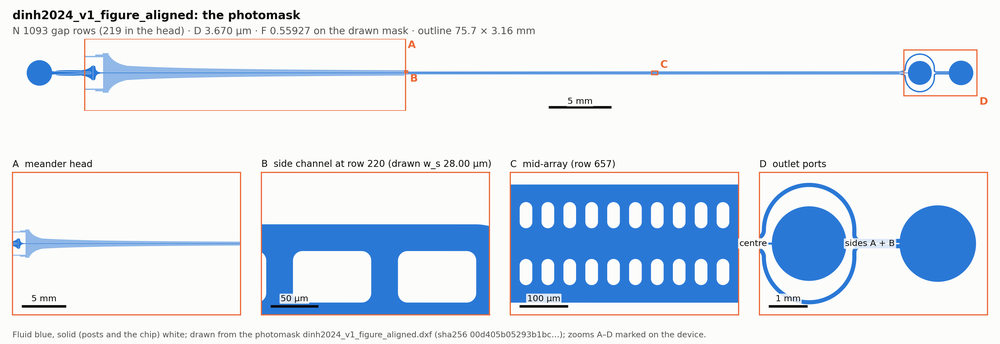

(preview; full resolution: tutorial_out/dissertation_figures/dinh2024_v1_figure_aligned_overview.png)


dinh2024_v1_figure_aligned (physics)

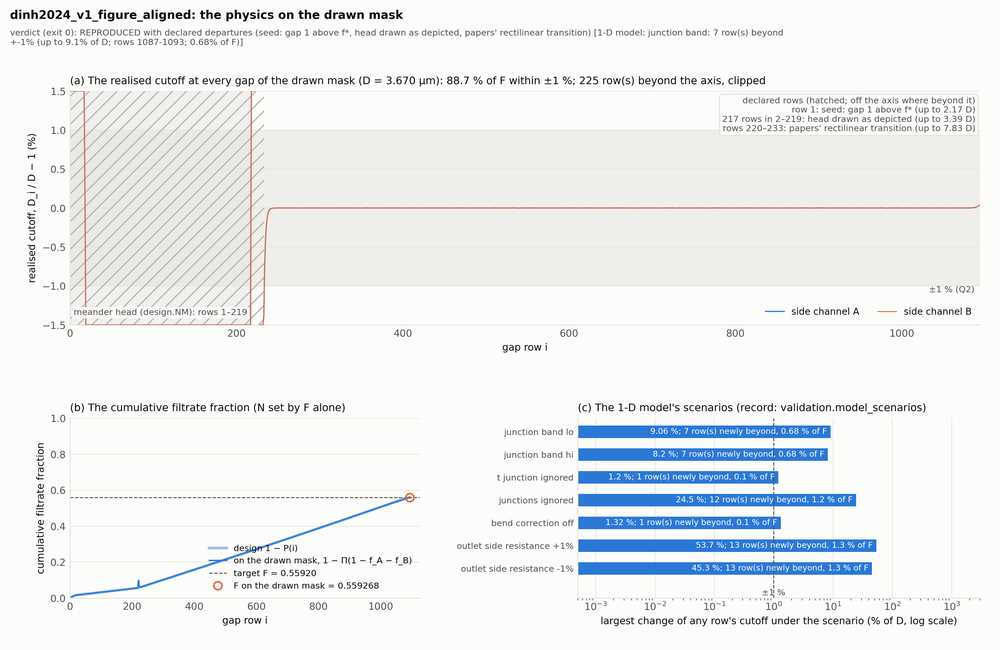

(preview; full resolution: tutorial_out/dissertation_figures/dinh2024_v1_figure_aligned_physics.png)


# dinh2024_v1_figure_aligned: provenance

| field | value |
|---|---|
| input (the record's `input` block, canonical JSON) sha256 | `6d7489f93fd5f9f40f560665b25831a1dd28ae8b255bbddddcf1cb01cdaab9c7` |
| code | opencif 1.0.0, stamp `9e4eb55a0affeef3` (44 files) |
| tests | `6340f50956101e9d` (16 files) |
| photomask | `dinh2024_v1_figure_aligned.dxf`, sha256 `00d405b05293b1bcbf9c57c37a6405da34dee5ec24f3014522f993a1656f5d43` (equal to the record's) |
| mode | reproduce |
| target cutoff D | 3.6700 µm (realised on the drawn mask 2.1709–28.7326 µm) |
| filtrate fraction F | target 0.559200, on the drawn mask 0.559268 |
| share of F within ±1 % of D | 0.8874 |
| declared rows | seed: gap 1 above f*: row 1; head drawn as depicted: 217 row(s) in rows 2–219; papers' rectilinear transition: rows 220–233 |
| gap rows N (head NM) | 1093 (219) |
| layout | linear, 1 leg(s) |
| the process floor | min feature 19 µm, depth 140 µm, gap 19 µm |
| narrowest side channel | planned 20.973 µm (`design.ws_min_um`); drawn 21.181 µm (`validation.passage`, straight side channel) |
| statuses | hard_checks PASS, validity_envelope INSIDE, chip_area NOT_GIVEN, aspect_ratio_of_CIF_channels WITHIN_LIMIT, length_budget_G9 NOT_GIVEN, drawn_mask_assessment RUN, physics_audit PASS, fabricated_or_measured NO, reproduction DESIGN_LEVEL, source_trace NAMED |
| verdict (exit) | REPRODUCED with declared departures (seed: gap 1 above f*, head drawn as depicted, papers' rectilinear transition) [1-D model: junction band: 7 row(s) beyond +-1% (up to 9.1% of D; rows 1087-1093; 0.68% of F)] (0) |


gifford2014_fig4_aligned (overview)

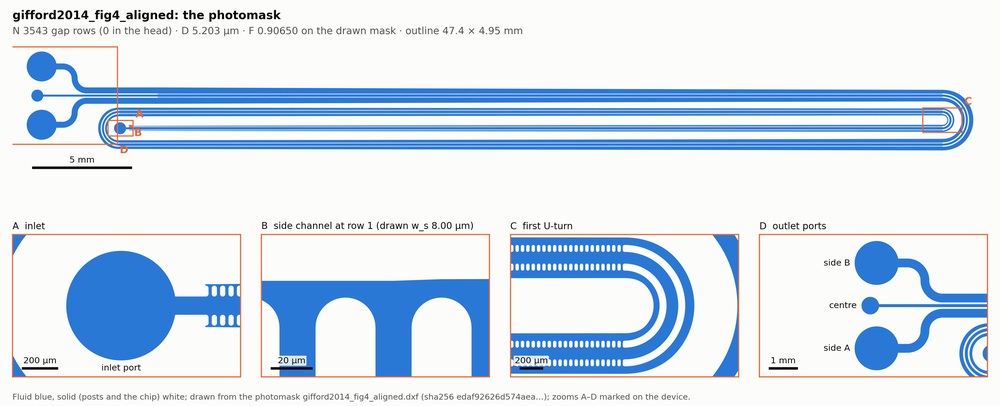

(preview; full resolution: tutorial_out/dissertation_figures/gifford2014_fig4_aligned_overview.png)


gifford2014_fig4_aligned (physics)

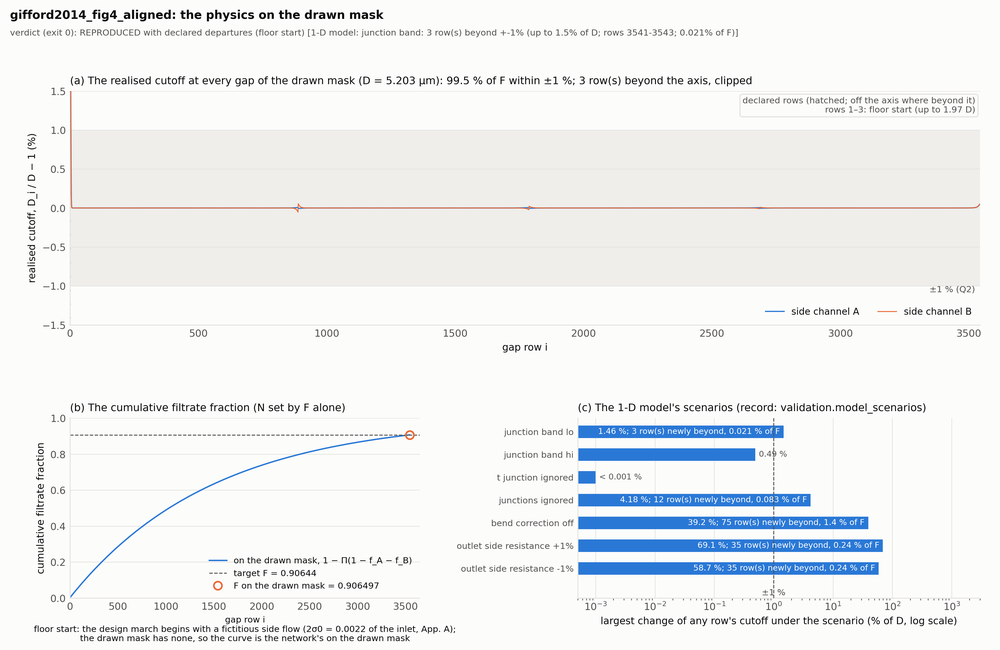

(preview; full resolution: tutorial_out/dissertation_figures/gifford2014_fig4_aligned_physics.png)


# gifford2014_fig4_aligned: provenance

| field | value |
|---|---|
| input (the record's `input` block, canonical JSON) sha256 | `25b2f3ffb28ae093fa290dc53f9e9be9de38f0daeacde24ec93e4d005dc38fe8` |
| code | opencif 1.0.0, stamp `9e4eb55a0affeef3` (44 files) |
| tests | `6340f50956101e9d` (16 files) |
| photomask | `gifford2014_fig4_aligned.dxf`, sha256 `edaf92626d574aea0dc9defed781e2f848def5c70fbaf9d70def345cc0ddf2e0` (equal to the record's) |
| mode | reproduce |
| target cutoff D | 5.2032 µm (realised on the drawn mask 5.2004–10.2287 µm) |
| filtrate fraction F | target 0.906440, on the drawn mask 0.906497 |
| share of F within ±1 % of D | 0.9953 |
| declared rows | floor start: rows 1–3 |
| gap rows N (head NM) | 3543 (0) |
| layout | paperclip, 4 leg(s) |
| the process floor | min feature 8 µm, depth 80 µm, gap 17.2 µm |
| narrowest side channel | planned 8.000 µm (`design.ws_min_um`); drawn 8.000 µm (`validation.passage`, straight side channel) |
| statuses | hard_checks PASS, validity_envelope INSIDE, chip_area NOT_GIVEN, aspect_ratio_of_CIF_channels WITHIN_LIMIT, length_budget_G9 NOT_GIVEN, drawn_mask_assessment RUN, physics_audit PASS, fabricated_or_measured NO, reproduction DESIGN_LEVEL, source_trace NAMED |
| verdict (exit) | REPRODUCED with declared departures (floor start) [1-D model: junction band: 3 row(s) beyond +-1% (up to 1.5% of D; rows 3541-3543; 0.021% of F)] (0) |


gifford2014_fig6_aligned (overview)

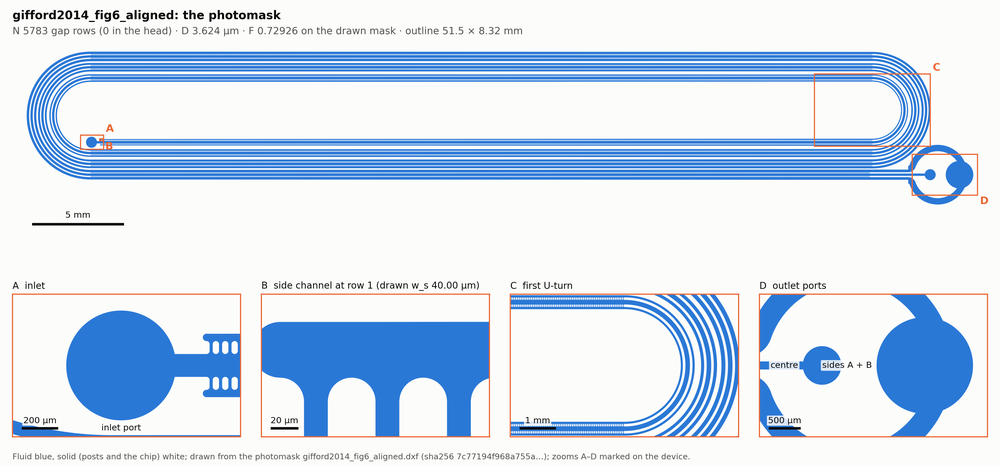

(preview; full resolution: tutorial_out/dissertation_figures/gifford2014_fig6_aligned_overview.png)


gifford2014_fig6_aligned (physics)

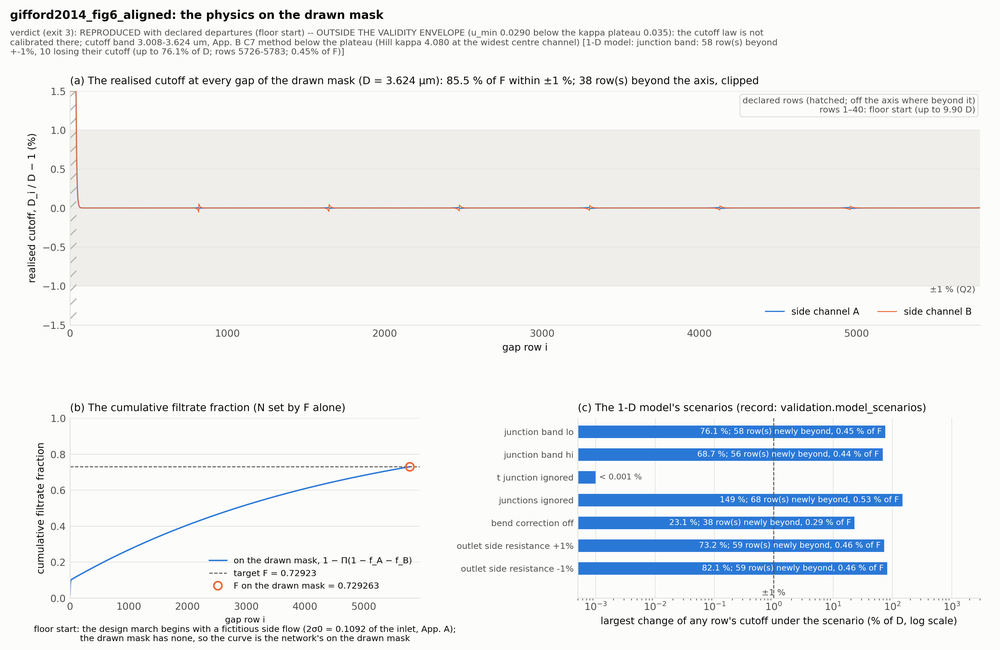

(preview; full resolution: tutorial_out/dissertation_figures/gifford2014_fig6_aligned_physics.png)


# gifford2014_fig6_aligned: provenance

| field | value |
|---|---|
| input (the record's `input` block, canonical JSON) sha256 | `65edf9ccb6a9c27f40d0b2ad6db27bdde95f17ff257c77ef75cfa4df7ac55f3e` |
| code | opencif 1.0.0, stamp `9e4eb55a0affeef3` (44 files) |
| tests | `6340f50956101e9d` (16 files) |
| photomask | `gifford2014_fig6_aligned.dxf`, sha256 `7c77194f968a755a71518a687fe905ac671e7566c0e1495780be64a36bd4add7` (equal to the record's) |
| mode | reproduce |
| target cutoff D | 3.6236 µm (realised on the drawn mask 3.6217–35.8660 µm) |
| filtrate fraction F | target 0.729230, on the drawn mask 0.729263 |
| share of F within ±1 % of D | 0.8548 |
| declared rows | floor start: rows 1–40 |
| gap rows N (head NM) | 5783 (0) |
| layout | paperclip, 7 leg(s) |
| the process floor | min feature 4.5 µm, depth 150 µm, gap 17.1 µm |
| narrowest side channel | planned 40.000 µm (`design.ws_min_um`); drawn 40.000 µm (`validation.passage`, straight side channel) |
| statuses | hard_checks PASS, validity_envelope OUTSIDE, chip_area NOT_GIVEN, aspect_ratio_of_CIF_channels WITHIN_LIMIT, length_budget_G9 NOT_GIVEN, drawn_mask_assessment RUN, physics_audit PASS, fabricated_or_measured NO, reproduction DESIGN_LEVEL, source_trace NAMED |
| verdict (exit) | REPRODUCED with declared departures (floor start) -- OUTSIDE THE VALIDITY ENVELOPE (u_min 0.0290 below the kappa plateau 0.035): the cutoff law is not calibrated there; cutoff band 3.008-3.624 um, App. B C7 method below the plateau (Hill kappa 4.080 at the widest centre channel) [1-D model: junction band: 58 row(s) beyond +-1%, 10 losing their cutoff (up to 76.1% of D; rows 5726-5783; 0.45% of F)] (3) |


xia2016_rs7_aligned (overview)

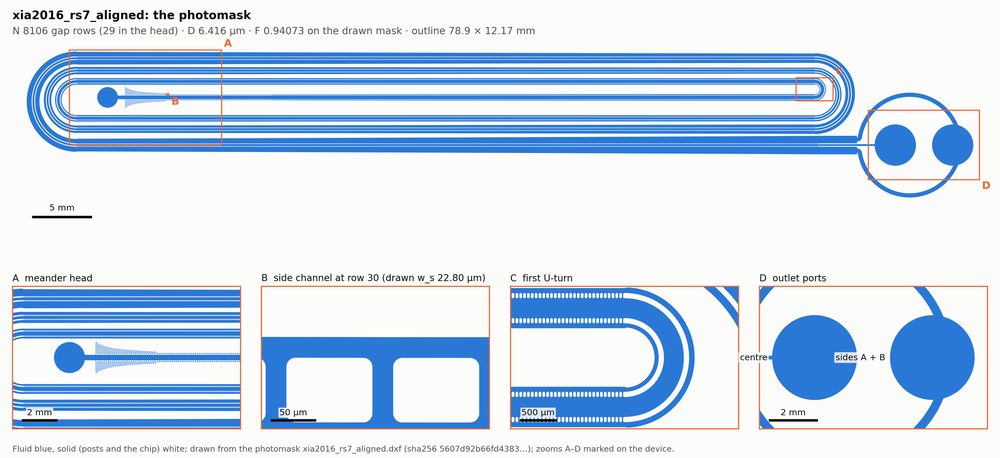

(preview; full resolution: tutorial_out/dissertation_figures/xia2016_rs7_aligned_overview.png)


xia2016_rs7_aligned (physics)

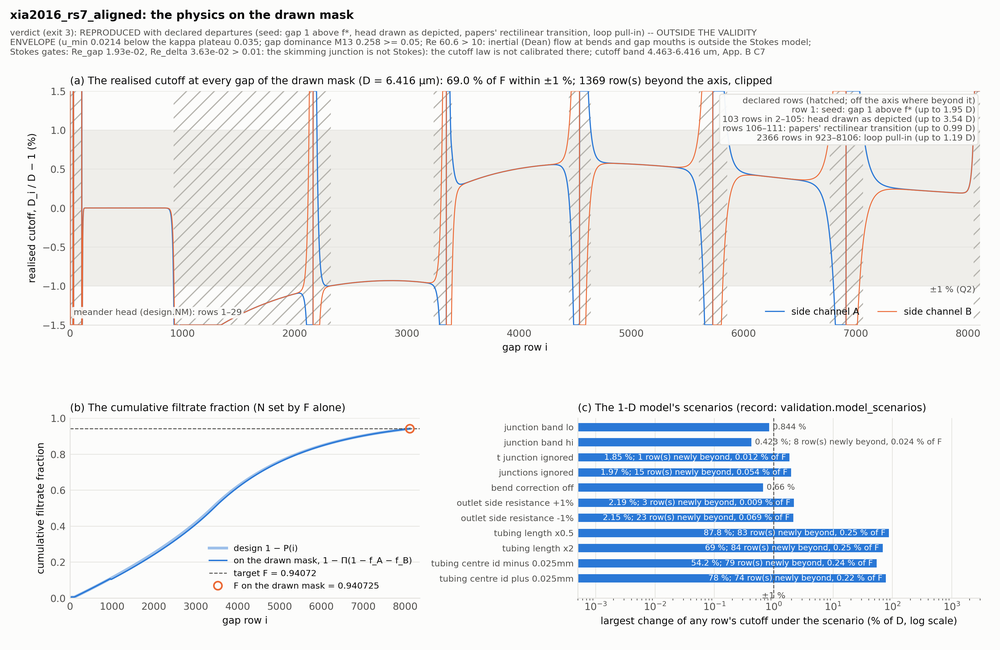

(preview; full resolution: tutorial_out/dissertation_figures/xia2016_rs7_aligned_physics.png)


# xia2016_rs7_aligned: provenance

| field | value |
|---|---|
| input (the record's `input` block, canonical JSON) sha256 | `509e9fc38e3e31bcd5b21ddd9590b386c293639cd4bfc9c9fd7b83c9c90600bd` |
| code | opencif 1.0.0, stamp `9e4eb55a0affeef3` (44 files) |
| tests | `6340f50956101e9d` (16 files) |
| photomask | `xia2016_rs7_aligned.dxf`, sha256 `5607d92b66fd4383e5246b544a5ad3fbf0de7279c901ad4aeffb2073f5ab6d0f` (equal to the record's) |
| mode | reproduce |
| target cutoff D | 6.4159 µm (realised on the drawn mask 0.0000–22.7193 µm) |
| filtrate fraction F | target 0.940720, on the drawn mask 0.940725 |
| share of F within ±1 % of D | 0.6898 |
| declared rows | seed: gap 1 above f*: row 1; head drawn as depicted: 103 row(s) in rows 2–105; papers' rectilinear transition: rows 106–111; loop pull-in: 2366 row(s) in rows 923–8106 |
| gap rows N (head NM) | 8106 (29) |
| layout | paperclip, 7 leg(s) |
| the process floor | min feature 16 µm, depth 140 µm, gap 16 µm |
| narrowest side channel | planned 22.796 µm (`design.ws_min_um`); drawn 22.799 µm (`validation.passage`, straight side channel) |
| statuses | hard_checks PASS, validity_envelope OUTSIDE, chip_area NOT_GIVEN, aspect_ratio_of_CIF_channels WITHIN_LIMIT, length_budget_G9 NOT_GIVEN, drawn_mask_assessment RUN, physics_audit PASS_OUTSIDE_ENVELOPE, fabricated_or_measured NO, reproduction DESIGN_LEVEL, source_trace NAMED |
| verdict (exit) | REPRODUCED with declared departures (seed: gap 1 above f*, head drawn as depicted, papers' rectilinear transition, loop pull-in) -- OUTSIDE THE VALIDITY ENVELOPE (u_min 0.0214 below the kappa plateau 0.035; gap dominance M13 0.258 >= 0.05; Re 60.6 > 10: inertial (Dean) flow at bends and gap mouths is outside the Stokes model; Stokes gates: Re_gap 1.93e-02, Re_delta 3.63e-02 > 0.01: the skimming junction is not Stokes): the cutoff law is not calibrated there; cutoff band 4.463-6.416 um, App. B C7 method below the plateau (Hill kappa 3.418 at the widest centre channel) [1-D model: junction band: 8 row(s) beyond +-1% (up to 0.8% of D; rows 8042-8049; 0.024% of F); last rows depend on the outlet tubing (84 rows beyond +-1% in its scenarios)] (3) |


In [33]:
FIGS = OUT / 'dissertation_figures'
FIGS.mkdir(exist_ok=True)
for n in REPRO:
    run_dir = OUT / 'repro' / n
    if not (run_dir / (n + '.json')).exists():
        continue
    p = subprocess.run([sys.executable, '-I', str(TREE / 'tools' / 'dissertation_figures.py'), 'build', str(run_dir), str(FIGS)],
                       capture_output=True, text=True)
    said = (p.stdout.strip().splitlines() or [''])[-1] if p.stdout else p.stderr[-300:]
    print(n, 'figures, exit code', p.returncode, said.replace(str(HERE) + os.sep, ''))
for n in REPRO:
    for kind in ('overview', 'physics'):
        f_ = FIGS / ('%s_%s.png' % (n, kind))
        if f_.exists():
            display(Markdown('%s (%s)' % (n, kind)))
            preview(f_, width=1000)
    pv = FIGS / ('%s_provenance.md' % n)
    if pv.exists():
        display(Markdown(pv.read_text()))

### 10.3 The taper-direction test (V13) on Gifford's Fig. 4

In a CIF leg, the side channels widen along the flow, so the sign of the slope of a leg's outer width gives its flow
direction (Gifford 2014, Fig. 1 caption). RC8 measured that slope on the Fig. 4 inset for the neighboring leg, through
the registration of each candidate layout, and compared it with the photomask's slope. The nested layout (legs 2 and
4, as the caption states) passes, whereas the path-order layout fails. The figure below is drawn from RC8's frozen
trace records, which hold widths only and no paper image.

exit 0


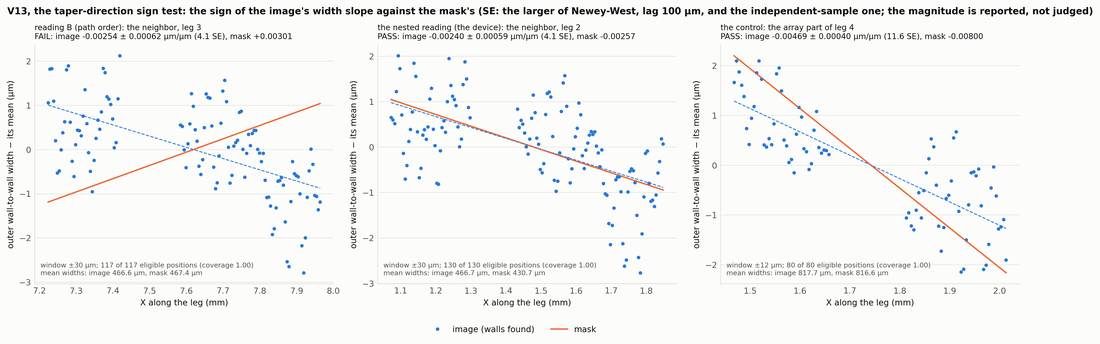

(preview; full resolution: tutorial_out/dissertation_figures/fig_taper_direction.png)
aligned_neighbour    PASS: image slope -0.00240 +- 0.00059 um/um (4.1 SE), mask -0.00257, 130 of 130 eligible positions, window +-30 um
pathorder_neighbour  FAIL: image slope -0.00254 +- 0.00062 um/um (4.1 SE), mask +0.00301, 117 of 117 eligible positions, window +-30 um
aligned_leg4         PASS: image slope -0.00469 +- 0.00040 um/um (11.6 SE), mask -0.00800, 80 of 80 eligible positions, window +-12 um


In [34]:
G4 = TREE / 'provenance' / 'rc7_traces' / 'results' / 'gifford'
p = subprocess.run([sys.executable, '-I', str(TREE / 'tools' / 'dissertation_figures.py'), 'v13', str(FIGS / 'fig_taper_direction'),
                    '%s=reading B (path order): the neighbor, leg 3' % (G4 / 'v13_pathorder_neighbour.json'),
                    '%s=the nested reading (the device): the neighbor, leg 2' % (G4 / 'v13_aligned_neighbour.json'),
                    '%s=the control: the array part of leg 4' % (G4 / 'v13_aligned_leg4.json')], capture_output=True, text=True)
print('exit', p.returncode)
preview(FIGS / 'fig_taper_direction.png', width=1100)
for k in ('aligned_neighbour', 'pathorder_neighbour', 'aligned_leg4'):
    v = json.load(open(G4 / ('v13_%s.json' % k)))
    print('%-20s %s: image slope %+.5f +- %.5f um/um (%.1f SE), mask %+.5f, %d of %d eligible positions, window +-%g um'
          % (k, v['verdict'], v['slope_image'], v['se_image'], abs(v['z_image']), v['slope_mask'], v['positions'],
             v['eligible'], v['window_um']))

### 10.4 What the reproductions do not show

RC8's register of discrepancies, which the repository keeps as `provenance/RC8_DISCREPANCIES.md` (with
`docs/LIMITATIONS.md`, item 28, for GIF4-1), records two open discrepancies. On Gifford's Fig. 4, the side channels of
the neighboring leg read about 18 µm per side wider on the image than the printed schedule draws them (GIF4-1, open).
On Xia's Fig. 3, panel f, the side-channel walls lie 36 to 40 µm inside those of the aligned mask (INV-4, open). Both
are stated in the register, and neither changes the generator.

## 11. opencif and the design code `CIF_v2.py`

Appendix A's table of results names the program behind Results 10 to 14 as "the design code `CIF_v2.py`". The
repository keeps it byte-frozen at `reference/CIF_v2.py` (md5 `0e0961a5...`) for the tests, and the package never
imports it. Instead, `opencif/physics/kernels.py` restates its kernels, which are the duct resistance `r` and its
inverse, the cubic kernel `g_cubic` and its inverse `x_of_f`, the laminar coefficient $c_2$, the shear coefficient,
the entrance length, the stadium post shape, and its pairing, process, and tolerance records, and
`tests/test_kernels.py` proves that they return the design code's numbers bit for bit. The tutorial itself imports
the design code as `C` (section 3.1), and the cell below uses it to run the design code's own reference device, with
$D$ = 2.17 µm and $F$ = 0.5592. The cutoff is the one that Dinh's printed $f^*$ = 1.04 × 10⁻⁴ at $w_c$ = 75 µm implies
through $\kappa_g$ at leading order (the glossary's 2.170; Dinh prints no cutoff in micrometers), and the filtrate
fraction is the 1-D prediction $F_{\mathrm{closed}}$ of App. B, claim C4, for Dinh's V1 (Dinh measured 0.505). Its
center channel narrows from 60 to 42 µm, which is Dinh's 75 to 52 µm rescaled so that the device passes the plateau
guard that refuses Dinh's own widths (`CIF_v2.lineage_request`; section 10).

The table below summarizes how the two programs relate (`docs/ALIGNMENT.md`; `docs/CIF_V2_REQUIREMENTS.md`, which
lists every requirement of the design code and its status in opencif).

| | `CIF_v2.py` (the design code) | opencif 1.0.0 (the generator) |
|---|---|---|
| kernels ($g$, $x(f)$, $r$, $\kappa_g$) | defines them | restates them in `opencif/physics/kernels.py`, equal to the design code's bit for bit (`tests/test_kernels.py`), and never imports `CIF_v2.py` |
| the march (Result 10) | `march` | `schedule.build` (the trace suite checks App. A's example) |
| widths from flows | `design()` uses the PE closure (spec v5, section 9; App. A, eq. 69), and its embedded physics core (`compile_unified`) uses an exact flow-prescribed closure, a Kirchhoff solve of the compiled pattern, and a width-correction loop | the exact gap-drop closure, which reduces to eq. 69 (AA17; section 4.4); opencif does not use the design code's physics core |
| the outlet | the PE outlet identity (Result 8) | the exact outlet closure (AA8, AA20) |
| geometry | linear, serpentine, and paperclip layouts with U-turns, folded side channels, stadium posts, ports, and leads (`Layout`, `build_mask`); a meander-head compiler (`compile_meander`, `write_dxf_meander`) for heads of arms, taper and decay regions, filleted, with 19 geometry validators | its own heads (the papers' arms and hairpins, and the packed and narrow heads), filter inlets, teardrop and ring outlets, and arrays, with every bend and junction corrected by exact solves and everything measured on the drawn mask |
| checks | the validator battery K/E/C/P/M/D/G/N/S/R and further families for its embedded cores and staged pipeline; the mask checks G17 to G23 on its own builds; the physics auditor P1 to P10 | the acceptance suite (sixteen test suites); every drawn mask measured (Q1, Q2, DRC); the design code's physics auditor, ported, on every photomask file (P0, R0, P1–P10, P6b, P9-AR, M14, and R6b, with P7 and P8 reported; section 7; `docs/LIMITATIONS.md`, item 6) |
| realized $F$ and $D$ | reports $F_{\mathrm{real}} \approx \eta F$ ($\eta$ = 0.903, measured on Dinh's V1) and a depth transfer bias on $D$, and applies neither | reports both on every build by the design code's own formulas and applies neither (`validation.design_code_reports`, B6 and B7), so $F$ remains the 1-D network's fraction on the drawn mask (LIMITATIONS 5; ALIGNMENT AG7i) |
| published devices | Gifford's Fig. 2 design curves (`gifford_fig2`, validator M19); the lineage geometry, which its plateau guard refuses (`lineage_request`) | presets of eight published designs, four of them built and traced on the papers' micrographs; Gifford's Fig. 2 from the planner (section 4.5; `tests/test_design_code.py`, section 6) |

In [35]:
t0 = time.time()
dev = C.design(C.reference_request())
print('CIF_v2 %s, design() in %.1f s' % (C.__version__, time.time() - t0))
print(dev.report())

CIF_v2 2.1.0, design() in 4.7 s
LADDER-ARRAY DEVICE  (Ladder-Array Design Specification v5)
  kernel / kappa        : cubic  /  4.9138   [PAIRED -- P1/P2]
  N (rows)              : 1774
  F  (model)            : 0.55930
  F  (realized ~ eta F) : 0.50505      eta = 0.903 (CALIBRATED)
  D                     : 2.1700 um
  delta*                : 0.4416 um   (invariant, S1)
  w_c                   : 60.0 -> 42.0 um
  w_s                   : 8.856 -> 35.86 um
  u = D/w_c             : 0.0362 .. 0.0517   (plateau: u >= 0.035)
  array length          : 86.9 mm   (budget 151.6 mm)
  folded rows           : 227   (of which 0 need borrowed slots -> G14)
  max Phi               : 28.8   (packing cap W/p = 33.2)
  DIRECT mass defect    : 8.1341e-03
------------------------------------------------------------------------------
  REGIME GATES
    gap dominance  max R_gap f / R_c : 0.0078   (< 0.05)
    Re (channel, max)                : 5.00
    Re_gap                           : 1.02e-03   (must b

### 11.1 The realized-yield factor and the transfer bias

Two lines of the report above are also recorded on every opencif build, computed by the design code's own formulas and
never applied (`validation.design_code_reports`; `docs/CIF_V2_REQUIREMENTS.md`, B6 and B7). The first is $\eta = 0.903$,
the measured ratio of Dinh's filtrate fraction (0.505) to the 1-D prediction (0.5592), a difference that Appendix B
closes with the 3-D flow at the outlet bifurcation (P-C4.2). opencif's $F$ is the 1-D value, and because the difference
depends on the outlet's geometry, a fabricated device's $F$ may fall short of the 1-D value by a similar amount
(`docs/LIMITATIONS.md`, item 5). The second is the transfer bias, which is the design code's estimate of how the cutoff
changes when $\kappa$, fitted on the channel shape of the calibration array, is used at a device's aspect ratio. By that
estimate, the true cutoff of this reference device would be about 15% above the predicted one. The design code and
opencif both report the bias and never apply it. Appendix B keeps the depth effect as a bounded factor folded into
$\kappa_{\mathrm{app}}$ (0.81–0.98), and with the cubic kernel the calibration depth does not enter the row count
(glossary; `docs/ALIGNMENT.md`, section 5). The report above still says that $\beta_{\mathrm{cal}}$ "swings N by ~27%",
which is fixed text about the $F_{\mathrm{lam}}$ pairing, since switching to that kernel requires
$\kappa_{\mathrm{flam}} = \kappa_{\mathrm{cubic}}/K_{\mathrm{depth}}(\beta_{\mathrm{cal}})$ (`CIF_v2.Pairing`). On the
cubic pairing that this device uses, $\beta_{\mathrm{cal}}$ enters only the transfer bias.

## 12. Micrograph traces (the companion notebook)

The device kits in `devices/` register the photomasks of the four published devices on the papers' own micrographs
(Gifford Fig. 4 and Fig. 6, Xia Fig. 3, and Dinh Fig. 2B) and measure how well they align. Those figures belong to the
publishers. Gifford 2014 and Dinh 2024 are © the Royal Society of Chemistry, with no Creative Commons license, and
their figures are reproduced with its permission, whereas Xia 2016 is CC BY 4.0. The six figures that the kits read are
in `notebooks/figures/`, outside opencif's MIT License (`NOTICE.md`). The companion notebook
`notebooks/opencif_traces.ipynb` takes them from that folder (each checked by its sha256), assembles each device
package from the repository, and runs its build, trace, measurement, and rendering, comparing every value with the
reference records that the kit carries (`devices/README.md`). Its outputs show the papers' images, so they carry the
same terms.

## 13. Exercises

1. At $F$ = 0.5 and with the parts of section 4.3, predict $N$ for $D$ = 3.5 µm from $N D^2$, and check the prediction
   with a plan. Then change $F$ to 0.6 at $D$ = 3.5 µm. Which of $N$ and the planned cutoff moves?
2. For $D$ = 3 µm, what is the widest center channel on the plateau? Plan a design 2 µm wider in strict mode and in
   evaluate mode, and read the verdicts.
3. Plan $D$ = 4 µm, $F$ = 0.5 with `meander=None` on the `generic19` process, and read the error it raises (a
   `SpecError`, which is exit 6 on the command line). Which width falls below which floor, and what remedies does the
   message list?
4. Repeat the comparison of section 4.4 for `examples/matrix/m15_linear_shear_nomeander_filter_teardrop.yaml`, whose
   center channel narrows at a constant wall shear. Because the width changes within each segment, take the PE side
   resistance from the plan's own segment resistance `Rc[i]` rather than from the width at the gap. Is the PE closure
   still a good approximation, and how does the gap flow `Qg` change from row to row? Look at the design code's M13
   number in the plan's gates (`PL.prepare`).
5. Build a paperclip with a ring outlet for $D$ = 5 µm, $F$ = 0.7 on a 25 × 75 mm chip. How many legs does the
   generator choose? Inspect the realized cutoff near the U-turns.
6. Open `presets/xia2016_rs7_aligned.yaml`. Which values are printed (P), measured (M), derived or fitted (D), assumed
   (A), or the generator's choice (G)? Why is its exit code 3?

### 13.1 Solutions

The cell below computes the solutions on opencif 1.0.0 with the calls that the exercises ask for, and the paragraphs
after it explain each answer. A course copy can hide this cell and the explanation that follows it. The cell plans
the designs rather than building them, so exercise 5 gives the number of legs and leaves the realized cutoff to a
build.

In [36]:
# Exercise 1. The row count scales as 1/D^2 at a fixed F, so the plan at D = 4 um predicts the plan at D = 3.5 um.
sol = OUT / 'solutions'
r4 = opencif.generate(4.0, 0.5, out=sol, check_only='plan', name='ex1_D4', **DC)
r35 = opencif.generate(3.5, 0.5, out=sol, check_only='plan', name='ex1_D3p5', **DC)
r35b = opencif.generate(3.5, 0.6, out=sol, check_only='plan', name='ex1_D3p5_F0p6', **DC)
d4, d35, d35b = (r.record['design'] for r in (r4, r35, r35b))
print('exercise 1: N D^2 = %d at D = 4 um predicts N = %d at D = 3.5 um, and the plan gives N = %d (F planned %.5f, '
      'D planned %.4f um)' % (d4['N'] * 16, round(d4['N'] * 16 / 3.5 ** 2), d35['N'], d35['F_planned'], d35['D_um']))
print('            at F = 0.6 the plan gives N = %d and D planned %.4f um, so N moves and the cutoff does not'
      % (d35b['N'], d35b['D_um']))

# Exercise 2. The plateau requires D/w_c >= 0.035 at the widest center width.
w_max = 3.0 / 0.035
for mode in ('strict', 'evaluate'):
    parts = dict(DC)
    parts['taper'] = ('constant', round(w_max + 2.0, 1))
    r = opencif.generate(3.0, 0.5, out=sol, check_only='plan', mode=mode, name='ex2_' + mode, **parts)
    print('exercise 2: widest center width on the plateau %.1f um; at %.1f um, %s mode gives exit %d (%s)'
          % (w_max, w_max + 2.0, mode, r.exit_code, r.verdict))

# Exercise 3. A sealed start without a head on the 19 um process.
try:
    opencif.generate(4.0, 0.5, meander=None, process='generic19', out=sol, check_only='plan', name='ex3')
    print('exercise 3: no error raised')
except Exception as e:
    print('exercise 3: %s:\n   %s' % (type(e).__name__, e))

# Exercise 4. The exact closure against the PE closure on a tapered device. The center channel narrows within each
# segment, so the PE side resistance is the plan's own segment resistance R_c(i) times P(i)/S(i), and the PE width is
# the one whose resistance over the segment length ell(i) equals it.
def closures(path):
    S.clear_caches()
    p = S.plan(SP.to_engine(SP.load(str(path)))[0])
    seg = np.arange(p.N - 1)
    w_pe = np.array([brentq(lambda w: S.rr(w, p.spec.h) * p.ell[i] * S.UM - p.Rc[i] * p.P[i] / p.S[i], 1e-3, 5e3)
                     for i in seg])
    rs_rel = p.Rs[seg] / (p.Rc[seg] * p.P[seg] / p.S[seg]) - 1
    dq = float(np.median(np.abs(np.diff(p.Qg[:p.N]) / p.Qg[:p.N - 1])))     # row-to-row change of the gap flow
    return p, float(np.max(np.abs(p.ws[seg] / w_pe - 1))), rs_rel, dq


M15 = TREE / 'examples' / 'matrix' / 'm15_linear_shear_nomeander_filter_teardrop.yaml'
p15, dw15, rs15, dq15 = closures(M15)
p_lin, dw_lin, rs_lin, dq_lin = closures(TREE / 'examples' / 'gifford_physics_linear.yaml')
S.clear_caches()
g15 = PL.prepare(SP.load(str(M15)), lambda m: None)[3]
print('exercise 4: m15 has N = %d, w_c from %.0f to %.0f um, f from %.2e to %.2e, and Q_gap/Q_in from %.3e to %.3e'
      % (p15.N, p15.wc[0], p15.wc[p15.N - 1], p15.f[0], p15.f[p15.N - 1], p15.Qg[0], p15.Qg[p15.N - 1]))
print('  largest relative difference of the side widths, exact against PE: %.1e on m15, %.1e on the straight device'
      % (dw15, dw_lin))
print('  R_s(exact) / R_s(PE) - 1 on m15: %.1e (median over the rows; %.1e to %.1e)'
      % (np.median(rs15), rs15.min(), rs15.max()))
print('  row-to-row change of the gap flow (median): %.1e on m15, %.1e on the straight device (2 f = %.1e)'
      % (dq15, dq_lin, 2.0 * p_lin.f[5]))
print('  M13 = %.3f on m15, against its gate of 0.05' % g15['M13_gap_dominance_max'])

# Exercise 5. A full check draws the outline in memory and chooses the legs; the realized cutoff needs a build.
r5 = opencif.generate(5.0, 0.7, chip=(25, 75), layout='paperclip', outlet='ring', out=sol, check_only=True,
                      name='ex5')
lay5 = r5.record.get('layout') or {}
print('exercise 5: exit %d (%s); legs %s' % (r5.exit_code, r5.verdict, lay5.get('n_legs', lay5.get('legs'))))

# Exercise 6. The provenance tags of the Xia preset and the reasons for its exit code.
head = [ln for ln in open(TREE / 'presets' / 'xia2016_rs7_aligned.yaml') if ln.startswith('#')]
print('exercise 6: the preset header has %d comment lines; its first lines are' % len(head))
print(''.join(head[:12]).rstrip())
print('the released build of this preset: exit %d, physics audit %s'
      % (FROZEN['xia2016_rs7_aligned']['exit_code'], FROZEN['xia2016_rs7_aligned']['physics_audit']))

exercise 1: N D^2 = 17984 at D = 4 um predicts N = 1468 at D = 3.5 um, and the plan gives N = 1466 (F planned 0.50008, D planned 3.5000 um)
            at F = 0.6 the plan gives N = 1938 and D planned 3.5000 um, so N moves and the cutoff does not


exercise 2: widest center width on the plateau 85.7 um; at 87.7 um, strict mode gives exit 5 (WOULD BE REFUSED: kappa plateau (u_min 0.0342 < 0.035 at the widest centre width 87.7 um, before the head's sealing search))


exercise 2: widest center width on the plateau 85.7 um; at 87.7 um, evaluate mode gives exit 3 (planned only (no outline: check_only='plan'): outside the envelope: kappa plateau (u_min 0.0342 < 0.035))


exercise 3: SpecError:
   a sealed start without a meander head draws a 4.37 um first side channel, below the 19.0 um process floor: enable a meander head (meander.enabled: true), use start.style: floor (Gifford's rule; it over-extracts at the entrance, rows declared only in gates.mode: reproduce: a new design usually FAILS Q2 on them), or use a finer process.  Also found before drawing: straight side channel w_s = 4.37 um (row 1) below w_min = max(F_min, h/AR_max) = max(19.00, 100.0/10) = 19.00 um (CIF_v2 Process.w_min and design(); spec v5 sec. 18; process.aspect_ratio_max): spec v5 G7 asks widths >= w_min, and G11 would draw that row as a fold, which opencif does not draw


exercise 4: m15 has N = 781, w_c from 80 to 56 um, f from 3.09e-04 to 6.28e-04, and Q_gap/Q_in from 3.085e-04 to 3.143e-04
  largest relative difference of the side widths, exact against PE: 1.0e-05 on m15, 2.5e-05 on the straight device
  R_s(exact) / R_s(PE) - 1 on m15: 2.4e-06 (median over the rows; -2.7e-05 to 3.1e-06)
  row-to-row change of the gap flow (median): 1.1e-04 on m15, 8.9e-04 on the straight device (2 f = 8.9e-04)
  M13 = 0.024 on m15, against its gate of 0.05


exercise 5: exit 0 (planned and outlined in memory (no photomask written): inside the envelope); legs 2
exercise 6: the preset header has 17 comment lines; its first lines are
# rc7 PRESET: Xia 2016 RS-7 aligned with Fig. 3 (the rc6 variant xia2016_rs7_depicted_fig3 with the taper of XIA-1).
#   centre_channel.shear_formula: parallel_plates (rc7, XIA-1): A DEPARTURE from spec v5 S16-b (constant shear with
#     C(alpha), S:456; "max gamma_dot via C(alpha) [NEVER 6]", S:606), REPRODUCE MODE ONLY.  The constant-shear taper
#     300 -> 150 um holds the parallel-plate maximum wall shear 6 Q / (w_c h^2), so w_c is proportional to the centre
#     flow; it puts leg 3's centre widths on panels d and e (218.1 / 186.1 um against 219.8 / 186.0; rc6's exact
#     C(alpha): 230.9 / 205.5), A: chosen with those panels in view, which are then consistency, not a test.  Xia's text
#     does not state the shear coefficient.  The true peak shear via C(alpha) is 1.34-1.57 x the parallel-plate value
#  

The printed lines give the six answers, which the paragraphs below explain in turn.

First, $N D^2$ is nearly constant at a fixed $F$ and channel shape (Result 13b), so the plan at $D$ = 4 µm predicts
the row count at 3.5 µm, and the printed plan lies close to the prediction, since $N D^2$ is constant only to a
fraction of a percent (section 4.3). At $F$ = 0.6 the row count grows, whereas the planned cutoff stays at 3.5 µm,
because $D$ fixes the lamina and $F$ then fixes only $N$ (Result 13c).

Second, the widest center channel on the plateau for $D$ = 3 µm is $D/0.035$, about 85.7 µm. Two micrometers wider,
the reduced size ratio falls below 0.035, so strict mode refuses the design on the $\kappa$ plateau (exit 5) before
anything is drawn, whereas evaluate mode plans it and reports it as outside the envelope (exit 3). The two printed
verdicts give the ratio that each mode found.

Third, the `SpecError` names the first side channel, which a sealed start without a head draws at the width that the
row-1 closure gives, $R_s(1) \approx R_c/f$ (section 4.4), and the 19 µm process floor of `generic19` below which that
width falls. The message lists three remedies, which are a meander head, Gifford's floor start (which over-extracts at
the entrance, so that its rows are declared only in reproduce mode and a new design usually fails Q2 on them), and a
finer process.

Fourth, the PE closure on `m15` takes the plan's own center resistance $R_c(i)$, because the center channel narrows
within each segment, so that $R_c(i)$ is the resistance of a tapered segment rather than that of a duct of width
$w_c(i)$. With it, the side widths of the two closures agree even more closely than on the straight device of section
4.4, as the second line of exercise 4's output shows. The reason lies in the gap flow. The exact closure differs from PE
only by the row-to-row change of the gap's pressure drop, $R_{\mathrm{gap}}[Q_{\mathrm{gap}}(i) -
Q_{\mathrm{gap}}(i+1)]$ (section 4.4). On the straight device, $f$ is constant, so the gap flow falls by the fraction
$2f$ from one row to the next. On the constant-shear taper, the center width falls with the center flow so that the wall
shear stays fixed (until the width reaches its floor), and the flow within a lamina of fixed width beside a wall of
fixed shear is itself nearly fixed. The center flow halves along the device ($F$ = 0.5), so the fraction $f$ doubles
(the first line), whereas the gap flow $fP$ hardly changes, and its row-to-row change is far smaller than $2f$ (the
fourth line). The last rows are the exception, because the width there has reached its 56 µm floor (`width_min_um`), $f$
is constant again, and the deviation of $R_s$ is again of order $2f\,\mathrm{M13}$, which gives the lower end of the
range on the third line. PE therefore remains a good approximation on the taper, and the printed M13 lies below its 0.05
gate.

Fifth, a full check plans the design, chooses the number of legs that fit the 25 × 75 mm chip, and draws the outline
in memory without writing a photomask, so the printed line gives the legs and the exit code that a build would give.
The realized cutoff near the U-turns requires a build, which is the same call without `check_only`, after which
`record['validation']['realised_cutoff']` and the `_physics.png` figure give it row by row. The rows at the U-turns
carry the exact curved-duct correction of the bends, and the bracket after the verdict (section 6) shows which rows
the uncertainty of the junction terms moves.

Finally, the header of the preset tags each value with its source, P, M, D, A, or G (section 10;
`docs/PRESET_PROVENANCE.md`), and the cell prints the first lines of that header. The released build of the preset has
exit code 3 because the device lies outside the validity envelope, below the $\kappa$ plateau and outside the gates of
gap dominance (M13), of the channel Reynolds number, and of the Stokes regime, as the planning cell of section 10
printed. Reproduce mode therefore draws the device and reports the departures instead of refusing it, and the last
printed line gives the exit code and the physics audit of the released build.

## 14. The reproducibility record

The last cell lists every file that this notebook wrote, together with its sha256, and records the environment in
which the notebook ran.

In [37]:
lines = ['opencif %s, code stamp %s, tests %s' % (opencif.__version__, PL.CODE['sha256'], env['tests_sha256']),
         'Python %s on %s; installed = tested versions: %s' % (env['python'], env['platform'], env['matches_lock']),
         'repository: %s, released code stamp %s (%s)' % (TREE.name, RELEASE['code_stamp'],
                                                           'equal' if RELEASE['code_stamp'] == PL.CODE['sha256'] else 'DIFFERENT')]
files = sorted(p for p in OUT.rglob('*') if p.is_file() and p.name != 'MANIFEST.txt')
older = {p for p in files if p.stat().st_mtime < RUN_START}     # files that an earlier run wrote and this one kept
if QUICK:
    lines.append('quick mode: this run planned the reproductions rather than building them')
lines += ['reproduction built by an earlier run of this notebook (photomask sha256 verified): %s, code stamp %s, written %s'
          % (n, v['code_stamp'], v['written']) for n, v in REUSED.items()]
if older:
    lines.append('%d of the %d files below were written by an earlier run of this notebook and are marked "earlier run"'
                 % (len(older), len(files)))
else:
    lines.append('every file below was written by this run')
lines.append('')
lines += ['%s  %s%s' % (sha256(p), p.relative_to(OUT), '  (earlier run)' if p in older else '') for p in files]
(OUT / 'MANIFEST.txt').write_text('\n'.join(lines) + '\n')
print('\n'.join(lines[:lines.index('')]))
print('%d files listed in %s' % (len(files), os.path.relpath(OUT / 'MANIFEST.txt', HERE)))

opencif 1.0.0, code stamp 9e4eb55a0affeef3, tests 6340f50956101e9d
Python 3.11.17 on Linux-6.18.44-fc-v153-x86_64-with-glibc2.39; installed = tested versions: True
repository: opencif-1.0.0, released code stamp 9e4eb55a0affeef3 (equal)
every file below was written by this run
131 files listed in tutorial_out/MANIFEST.txt
